# Preprocessing audit: `all_removals`

Before building model-ready data: what in `analysis_measurement` is **duplicated**, **wrong**, an **outlier**, **doesn't belong**, or **unevenly sampled**, and how much each fix would cost.

- **Read-only.** The warehouse files are only read (through an in-memory DuckDB, so `warehouse.duckdb` is never opened). Nothing is removed or corrected here.
- Each check becomes a **flag**. Section 8 counts what would remain if each flag were turned into an exclusion. **Nothing is applied**; that is a decision for the next stage.
- Three files are written to `data/processed/preprocessing_audit/all_removals/`: `measurement_flags.parquet`, `pair_features.parquet` and `rule_impact.csv`.

Run on a compute node (about 32 GB): `jupyter nbconvert --to html --execute --ExecutePreprocessor.timeout=-1 notebooks/qa/preprocessing_audit.ipynb`

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Project root: the nearest folder at or above this one with etl/ and config/
# (works from any notebooks/ subfolder).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "etl").is_dir() and (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

from analysis import audit_utils as au
from etl.build_views import DEFAULT_MIN_SAMPLES, DEFAULT_MIN_YEARS
from etl.common import wq_rules
from etl.common.config import load_config
from etl.common.nhdplus import find_huc8_geodatabase
from etl.common.warehouse import warehouse_dir

# Where data/ lives: the repo on the cluster (DAM_REMOVAL_PROJECT_ROOT overrides it, as in the ETL).
DATA_ROOT = Path(os.environ.get("DAM_REMOVAL_PROJECT_ROOT", ROOT))
CASE_STUDY = "all_removals"
cfg = load_config(CASE_STUDY, project_root=DATA_ROOT)
WAREHOUSE = warehouse_dir(cfg)
OUTPUT_DIR = DATA_ROOT / "data" / "processed" / "preprocessing_audit" / CASE_STUDY

window = cfg.get("wq_window", {}) or {}
YEARS_BEFORE = int(window.get("years_before", 3))
YEARS_AFTER = int(window.get("years_after", 3))
eligibility = cfg.get("eligibility", {}) or {}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
# ---- Settings: exploratory starting points, not decisions ----
SAVE_OUTPUTS = True
READ_NHDPLUS = True          # dam/station reach attributes for section 6 (slow first run, then cached)

MAD_THRESHOLD = 5.0          # |robust z| above this is an outlier flag
MAD_MIN_N = 10               # station-series with fewer values aren't screened
SNAP_LIMIT_M = 500           # station moved farther than this to reach a stream
SALINE_SC = 3000             # station median specific conductance (uS/cm) above this: brackish/saline
COLOCATED_M = 200            # stations on the same reach closer than this can be duplicates
RULE_MIN_SAMPLES, RULE_MIN_YEARS = 6, 2   # stricter than the current 3 samples / 2 years per side
RULE_MIN_SHARED_MONTHS = 3   # calendar months sampled both before and after removal
MIN_PAIRS_PER_SERIES = 20
DISTANCE_OFFSET_KM = 0.1     # log10(distance + offset) keeps 0 km defined

# Right-skewed, positive parameters are screened on log10 (as in analysis_eda.ipynb).
LOG_PARAMETERS = ["turbidity", "specific_conductance", "nitrate", "ammonia", "orthophosphate", "phosphorus", "tds"]
# Tighter than wq_rules.PLAUSIBLE_RANGES (which only drops impossible values): (low, high).
SUSPICIOUS = {"water_temp": (None, 35), "ph": (4, 11), "dissolved_oxygen": (None, 20),
              "do_saturation": (None, 200), "specific_conductance": (None, 10000), "turbidity": (None, 2000),
              "phosphorus": (None, 10), "orthophosphate": (None, 5), "nitrate": (None, 30),
              "ammonia": (None, 10), "tds": (None, 10000)}
ZERO_IMPLAUSIBLE = ["ph", "specific_conductance", "tds"]
NUTRIENTS = ["nitrate", "ammonia", "orthophosphate", "phosphorus"]   # a reported 0 should be censored
NO_UNIT_SLIP = ["ph", "water_temp", "do_saturation", "turbidity"]      # skipped by the x1000 check

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
con, VIEWS = au.connect(WAREHOUSE, YEARS_BEFORE, YEARS_AFTER,
                        int(eligibility.get("min_samples", DEFAULT_MIN_SAMPLES)),
                        int(eligibility.get("min_years", DEFAULT_MIN_YEARS)),
                        threads=os.environ.get("SLURM_CPUS_PER_TASK"), temp_dir=OUTPUT_DIR / "_duckdb_tmp")
HAS = set(VIEWS)


def q(sql):
    return con.sql(sql).df()


def save(frame, name):
    if SAVE_OUTPUTS:
        au.save_output(frame, name, OUTPUT_DIR)
    return frame


def sql_list(values):
    return ", ".join("'" + str(v) + "'" for v in values)


SERIES = au.series_sql()
LOG_LIST = sql_list(LOG_PARAMETERS)

# m: cleaned results; am: analysis rows (measurement x dam); pairs: one row per dam-station pair.
con.execute(f"CREATE TEMP TABLE m AS SELECT *, {SERIES} AS series, month(sample_date) AS month FROM wq_measurement")
con.execute(f"CREATE TEMP TABLE am AS SELECT *, {SERIES} AS series, AR_ID || ' | ' || station_id AS pair "
            "FROM analysis_measurement")
con.execute("""
    CREATE TEMP TABLE pairs AS
    SELECT AR_ID, station_id, pair, any_value(side) AS side, any_value(network_distance_km) AS network_distance_km,
           any_value(removal_year) AS removal_year, count(*) AS rows
    FROM am GROUP BY AR_ID, station_id, pair
""")
print(f"{cfg.name}: window -{YEARS_BEFORE}/+{YEARS_AFTER} years; reading {WAREHOUSE}")

all_removals: window -5/+5 years; reading /courses/DS5500.202710/teams/team4/data/warehouse/all_removals


## 1. How the joins expand the data

Each cleaned result is joined to **every dam linked to its station**, so one measurement can appear in several pairs. **How to read it:** `rows_per_measurement` above 1 is reuse, not duplication, as long as the copies agree (checked below the table). It still matters for the models: reused rows aren't independent observations.

In [4]:
expansion = au.counts_table(con, {
    "wq_measurement (cleaned results)": "SELECT measurement_id, station_id, series FROM m",
    "x every linked dam with a removal year": f"SELECT measurement_id, station_id, AR_ID, {SERIES} AS series FROM measurement_window",
    "  ... pre/post years only": f"SELECT measurement_id, station_id, AR_ID, {SERIES} AS series FROM measurement_window WHERE period IN ('pre', 'post')",
    "analysis_measurement (has_both pair-series)": "SELECT measurement_id, station_id, AR_ID, series FROM am",
})
expansion["rows_per_measurement"] = (expansion["rows"] / expansion["measurements"]).round(2)
differ = con.sql("""SELECT count(*) FROM (SELECT measurement_id FROM am GROUP BY 1
                    HAVING count(DISTINCT result_value_std) > 1 OR count(DISTINCT sample_date) > 1
                        OR count(DISTINCT station_id) > 1)""").fetchone()[0]
print(f"Measurements whose copies disagree: {differ} (0 means every repeated row is reuse for another dam)")
expansion

Measurements whose copies disagree: 0 (0 means every repeated row is reuse for another dam)


,stage,rows,measurements,stations,series,dams,pairs,rows_per_measurement
0,wq_measurement (cleaned results),412597,412597,2789,21,NaN,NaN,1.00
1,x every linked dam with a removal year,2810179,412597,2789,21,326.0,9394.0,6.81
2,... pre/post years only,938406,370221,2555,21,310.0,5191.0,2.53
3,analysis_measurement (has_both pair-series),69747,46236,87,15,54.0,133.0,1.51


## 2. Duplicates and repeated readings

The cleaning step already removed exact repeats and the same result filed under two activities at the same time (spec 3.6.5). What could remain:

| check | what it means |
|---|---|
| same result, different method ID | one result reported twice under two method codes |
| same station, day, series and value at a different time | likely a double report |
| same, but from NWIS and STORET | one agency re-publishing the other's data |
| co-located stations with identical values | two station IDs on the same reach within `COLOCATED_M`, same series, day and value: likely one sample under two IDs |

**How to read it:** `extra_rows` is how many rows a "keep one copy" rule would drop. Several readings on one day are **not** treated as duplicates; that is the second table.

In [5]:
hav = au.haversine_m_sql("a.latitude", "a.longitude", "b.latitude", "b.longitude")
con.execute(f"""
    CREATE TEMP TABLE colocated AS
    SELECT x.measurement_id AS id_a, y.measurement_id AS id_b, x.provider AS provider_a, y.provider AS provider_b
    FROM wq_station a JOIN wq_station b ON a.NHDPlusID = b.NHDPlusID AND a.station_id < b.station_id AND {hav} <= {COLOCATED_M}
    JOIN m x ON x.station_id = a.station_id
    JOIN m y ON y.station_id = b.station_id AND y.sample_date = x.sample_date AND y.series = x.series
         AND y.result_value_std = x.result_value_std
""")
# Copies a "keep one" rule would drop: all but the lowest measurement_id per group; for
# co-located stations, the non-NWIS copy (else the second station's).
con.execute("""
    CREATE TEMP TABLE duplicate_copies AS
    SELECT measurement_id, 'same station/day/series/value' AS reason FROM (
        SELECT measurement_id, row_number() OVER (PARTITION BY station_id, sample_date, series, result_value_std
                                                  ORDER BY measurement_id) AS k
        FROM m) WHERE k > 1
    UNION ALL
    SELECT CASE WHEN provider_b = 'NWIS' AND provider_a <> 'NWIS' THEN id_a ELSE id_b END, 'co-located station copy'
    FROM colocated
""")
duplicates = q("""
    WITH a AS (SELECT count(*) AS n FROM m GROUP BY station_id, organization_id, activity_id, sample_date, sample_time,
                   parameter, sample_fraction, result_value_raw, result_unit_raw, detection_condition HAVING count(*) > 1),
    c AS (SELECT count(*) AS n, count(DISTINCT provider) AS providers FROM m
          GROUP BY station_id, sample_date, series, result_value_std HAVING count(*) > 1)
    SELECT 'same result, different method ID' AS check_name, count(*) AS groups, coalesce(sum(n) - count(*), 0) AS extra_rows FROM a
    UNION ALL SELECT 'same station/day/series/value, different time', count(*), coalesce(sum(n) - count(*), 0) FROM c
    UNION ALL SELECT '  ... of which across NWIS and STORET', count(*), coalesce(sum(n) - count(*), 0) FROM c WHERE providers > 1
    UNION ALL SELECT 'co-located stations with identical values', count(*), count(*) FROM colocated
""")
duplicates

,check_name,groups,extra_rows
0,"same result, different method ID",0,0.0
1,"same station/day/series/value, different time",4735,8741.0
2,... of which across NWIS and STORET,0,0.0
3,co-located stations with identical values,15887,15887.0


**Several readings on the same day** per station and series. `depth_profile_days` have samples at several depths (lakes, deep pools). The other multi-reading days are repeated readings at one spot. `rows_if_daily` is what a hypothetical "one value per station, series and day" aggregation would leave. It isn't applied.

In [6]:
same_day = q("""
    WITH g AS (SELECT series, count(*) AS n, count(DISTINCT depth_m) AS depths
               FROM m GROUP BY station_id, series, sample_date)
    SELECT series, sum(n) AS rows,
           round(100 * coalesce(sum(n) FILTER (WHERE n > 1), 0) / sum(n), 1) AS pct_rows_on_multi_reading_days,
           count(*) FILTER (WHERE n > 1 AND depths > 1) AS depth_profile_days,
           count(*) FILTER (WHERE n > 1 AND depths <= 1) AS other_multi_reading_days,
           count(*) AS rows_if_daily
    FROM g GROUP BY series ORDER BY rows DESC
""")
same_day

,series,rows,pct_rows_on_multi_reading_days,depth_profile_days,other_multi_reading_days,rows_if_daily
0,water_temp,67267.0,28.8,253,1943,50064
1,ph,61394.0,44.7,254,11692,45884
2,specific_conductance,58990.0,45.4,240,11107,43529
3,dissolved_oxygen,48224.0,13.1,264,1399,43571
4,phosphorus (Total),32895.0,6.4,1,744,31538
5,orthophosphate (Dissolved),22491.0,8.1,43,704,21425
6,tds,21427.0,1.2,2,123,21293
7,orthophosphate (Total),18027.0,0.8,0,70,17957
8,turbidity,17294.0,13.7,39,738,15701
9,phosphorus (Dissolved),15237.0,3.8,0,242,14900


## 3. Values that passed cleaning but look wrong

Cleaning only drops impossible values (`wq_rules.PLAUSIBLE_RANGES`, e.g. pH 0–14). These flags catch values inside those limits that are still suspect:

- `zero`: exactly 0 where that can't happen (pH, conductance, TDS), or a nutrient reported as 0 instead of "below detection";
- `at_limit`: exactly on a `PLAUSIBLE_RANGES` limit (e.g. DO = 25), typical of instrument caps or entry codes;
- `suspicious`: beyond the tighter `SUSPICIOUS` limits in the settings;
- `x1000`: about 1000× (or 1/1000×) the station's median, a likely mg/µg (or µS/mS) slip;
- `unit_assumed`: share of nutrient values whose N/P basis was assumed (reported as bare mg/L), for context only.

In [7]:
limits = pd.DataFrame([{"parameter_std": p, "plausible_low": lo, "plausible_high": hi,
                        "suspicious_low": SUSPICIOUS.get(p, (None, None))[0], "suspicious_high": SUSPICIOUS.get(p, (None, None))[1]}
                       for p, (lo, hi) in wq_rules.PLAUSIBLE_RANGES.items()])
limits[["suspicious_low", "suspicious_high"]] = limits[["suspicious_low", "suspicious_high"]].astype("float64")
con.register("limits", limits)
con.execute(f"""
    CREATE TEMP TABLE value_flags AS
    WITH s AS (SELECT station_id, series, median(result_value_std) AS med FROM m
               WHERE NOT is_censored AND result_value_std > 0 GROUP BY ALL HAVING count(*) >= {MAD_MIN_N})
    SELECT m.measurement_id, m.parameter_std, m.unit_basis_assumed,
           m.result_value_std = 0 AND (m.parameter_std IN ({sql_list(ZERO_IMPLAUSIBLE)})
               OR (m.parameter_std IN ({sql_list(NUTRIENTS)}) AND NOT m.is_censored)) AS f_zero,
           m.result_value_std = l.plausible_high OR (m.result_value_std = l.plausible_low AND l.plausible_low <> 0) AS f_at_limit,
           coalesce(m.result_value_std < l.suspicious_low OR m.result_value_std > l.suspicious_high, FALSE) AS f_suspicious,
           CASE WHEN m.parameter_std NOT IN ({sql_list(NO_UNIT_SLIP)}) AND m.result_value_std > 0 AND NOT m.is_censored
                THEN abs(abs(log10(m.result_value_std / s.med)) - 3) <= log10(1.5) END IS TRUE AS f_x1000
    FROM m JOIN limits l USING (parameter_std) LEFT JOIN s USING (station_id, series)
""")
q("""
    SELECT parameter_std, count(*) AS rows, sum(f_zero::INT) AS zero, sum(f_at_limit::INT) AS at_limit,
           sum(f_suspicious::INT) AS suspicious, sum(f_x1000::INT) AS x1000,
           round(100 * avg((f_zero OR f_at_limit OR f_suspicious OR f_x1000)::INT), 2) AS pct_any,
           round(100 * avg(unit_basis_assumed::INT), 1) AS pct_unit_assumed
    FROM value_flags GROUP BY 1 ORDER BY rows DESC
""")

,parameter_std,rows,zero,at_limit,suspicious,x1000,pct_any,pct_unit_assumed
0,water_temp,67267,0.0,9.0,100.0,0.0,0.16,0.0
1,ph,61394,0.0,0.0,24.0,0.0,0.04,0.0
2,specific_conductance,58990,0.0,0.0,0.0,125.0,0.21,0.0
3,phosphorus,48274,27.0,0.0,9.0,0.0,0.07,4.5
4,dissolved_oxygen,48224,0.0,0.0,65.0,0.0,0.13,0.0
5,orthophosphate,40530,601.0,0.0,9.0,0.0,1.51,11.4
6,tds,21427,0.0,0.0,5.0,0.0,0.02,0.0
7,nitrate,20333,414.0,0.0,101.0,1.0,2.54,32.0
8,turbidity,17294,0.0,0.0,0.0,0.0,0.00,0.0
9,ammonia,16859,2.0,0.0,0.0,0.0,0.01,0.0


**Related measurements that disagree**, within the same sampling visit (same station and `activity_id`; only uncensored values, one value per series per visit):

- a part larger than its whole: dissolved P > total P, orthophosphate > total P (beyond 10% and 0.005 mg/L);
- TDS / specific conductance outside 0.4–1.0 (typical is 0.55–0.75);
- reported DO saturation more than 15 points from the value computed from DO and water temperature (sea-level formula, so high sites read a little high).

Both measurements of a disagreeing visit are flagged.

In [8]:
con.execute("""
    CREATE TEMP TABLE visit AS
    SELECT measurement_id, station_id, activity_id, series, result_value_std AS v FROM m
    WHERE NOT is_censored AND activity_id IS NOT NULL AND result_value_std IS NOT NULL
    QUALIFY count(*) OVER (PARTITION BY station_id, activity_id, series) = 1
""")
pair_check = lambda name, a, b, violation: f"""
    SELECT '{name}' AS check_name, x.measurement_id AS id_a, y.measurement_id AS id_b, NULL::BIGINT AS id_c, {violation} AS bad
    FROM visit x JOIN visit y ON x.station_id = y.station_id AND x.activity_id = y.activity_id
    WHERE x.series = '{a}' AND y.series = '{b}'"""
checks = [
    pair_check("dissolved P > total P", "phosphorus (Dissolved)", "phosphorus (Total)", "x.v > 1.1 * y.v AND x.v - y.v > 0.005"),
    pair_check("orthophosphate > total P", "orthophosphate (Dissolved)", "phosphorus (Total)", "x.v > 1.1 * y.v AND x.v - y.v > 0.005"),
    pair_check("TDS / conductance outside 0.4-1.0", "tds", "specific_conductance", "y.v > 0 AND (x.v / y.v < 0.4 OR x.v / y.v > 1.0)"),
    f"""SELECT 'DO saturation off by > 15 points', x.measurement_id, s.measurement_id, t.measurement_id,
               abs(s.v - 100 * x.v / {au.do_saturation_sql('t.v')}) > 15
        FROM visit x
        JOIN visit t ON t.station_id = x.station_id AND t.activity_id = x.activity_id AND t.series = 'water_temp'
        JOIN visit s ON s.station_id = x.station_id AND s.activity_id = x.activity_id AND s.series = 'do_saturation'
        WHERE x.series = 'dissolved_oxygen'""",
]
con.execute("CREATE TEMP TABLE consistency AS " + " UNION ALL ".join(checks))
con.execute("""CREATE TEMP TABLE inconsistent AS
               SELECT DISTINCT id FROM (SELECT unnest([id_a, id_b, id_c]) AS id FROM consistency WHERE bad)
               WHERE id IS NOT NULL""")
q("""SELECT check_name, count(*) AS visits_compared, count(*) FILTER (WHERE bad) AS disagree,
            round(100 * avg(bad::INT), 2) AS pct_disagree FROM consistency GROUP BY 1 ORDER BY 1""")

,check_name,visits_compared,disagree,pct_disagree
0,DO saturation off by > 15 points,11827,2327,19.68
1,TDS / conductance outside 0.4-1.0,9590,486,5.07
2,dissolved P > total P,13198,109,0.83
3,orthophosphate > total P,14871,140,0.94


## 4. Outliers within each station

A robust z-score per station and series: `z = (x − median) / (1.4826 × MAD)`. It is comparable to an ordinary z-score but isn't pulled by the outliers it is looking for. Log10 is used for the skewed parameters. The median and MAD come from uncensored values only. Station-series with fewer than `MAD_MIN_N` values are not screened (`not_screened`). If more than half of a station's values are identical, MAD is 0, so the mean absolute deviation is used instead.

**How to read it:** if `pct_z>5` is much smaller than `pct_z>3.5` and close to `pct_z>7`, the values beyond 5 form a separate tail (likely errors) and the threshold choice matters little. Real storm or sediment-pulse values can also be flagged, which is why these are flags, not deletions.

In [9]:
au.robust_z(con, f"""
    SELECT measurement_id, station_id, series, parameter_std, is_censored,
           CASE WHEN parameter_std IN ({LOG_LIST}) THEN CASE WHEN result_value_std > 0 THEN log10(result_value_std) END
                ELSE result_value_std END AS x
    FROM m""", ["station_id", "series"], "robust", MAD_MIN_N, reference_filter="NOT is_censored")
q(f"""
    SELECT parameter_std, count(*) AS rows,
           count(*) FILTER (WHERE robust_z IS NULL) AS not_screened,
           round(100 * avg((abs(robust_z) > 3.5)::INT), 2) AS "pct_z>3.5",
           round(100 * avg((abs(robust_z) > {MAD_THRESHOLD})::INT), 2) AS "pct_z>{MAD_THRESHOLD:g}",
           round(100 * avg((abs(robust_z) > 7)::INT), 2) AS "pct_z>7",
           count(DISTINCT station_id) FILTER (WHERE abs(robust_z) > {MAD_THRESHOLD}) AS stations_flagged
    FROM robust GROUP BY 1 ORDER BY rows DESC
""")

,parameter_std,rows,not_screened,pct_z>3.5,pct_z>5,pct_z>7,stations_flagged
0,water_temp,67267,4439,0.53,0.15,0.05,29
1,ph,61394,4839,1.62,0.51,0.19,145
2,specific_conductance,58990,4531,2.21,1.11,0.65,172
3,phosphorus,48274,3915,2.57,0.85,0.24,117
4,dissolved_oxygen,48224,4207,0.74,0.18,0.06,46
5,orthophosphate,40530,5026,2.43,0.39,0.03,49
6,tds,21427,1251,1.64,0.85,0.45,85
7,nitrate,20333,1880,2.59,0.70,0.33,69
8,turbidity,17294,2766,1.93,0.66,0.23,58
9,ammonia,16859,872,3.12,1.13,1.04,13


In [10]:
# All measurement-level flags in one table (saved): one row per cleaned result.
measurement_flags = q(f"""
    SELECT m.measurement_id, m.station_id, m.series,
           v.f_zero, v.f_at_limit, v.f_suspicious, v.f_x1000,
           m.measurement_id IN (SELECT id FROM inconsistent) AS f_inconsistent,
           coalesce(abs(r.robust_z) > {MAD_THRESHOLD}, FALSE) AS f_outlier, r.robust_z,
           m.measurement_id IN (SELECT measurement_id FROM duplicate_copies) AS f_duplicate_copy
    FROM m JOIN value_flags v USING (measurement_id) LEFT JOIN robust r USING (measurement_id)
""")
con.register("measurement_flags", measurement_flags)
save(measurement_flags, "measurement_flags.parquet")
flag_cols = [c for c in measurement_flags.columns if c.startswith("f_")]
print("Share of cleaned results flagged (%):")
(100 * measurement_flags[flag_cols].mean()).round(3).to_frame("pct").T

Share of cleaned results flagged (%):


,f_zero,f_at_limit,f_suspicious,f_x1000,f_inconsistent,f_outlier,f_duplicate_copy
pct,0.253,0.002,0.078,0.031,2.042,0.561,5.841


## 5. Data that may not belong in the analysis

**Stations**, using what the warehouse already stores:
- `saline`: median specific conductance above `SALINE_SC` (fresh water is usually well under 1,500 µS/cm);
- `non_riverine`: the name suggests a marsh, bay, estuary, lake, pond, reservoir, slough, lagoon or canal, or the NHDPlus reach is a canal, connector or coastline;
- `far_snap`: moved more than `SNAP_LIMIT_M` to reach a stream, so it may be on the wrong reach;
- `bad_drainage_area`: no upstream area, the NHDPlus −9999 sentinel, or a truncated watershed;
- `name_mismatch` (context only): the station's name doesn't mention its reach's river. Weak on its own, strong together with `far_snap`.

**Pairs and series:**
- `overlap`: another removal linked to the same station falls inside this pair's window, so a change can't be attributed to one dam;
- `thin`: fewer than `RULE_MIN_SAMPLES` samples or `RULE_MIN_YEARS` years on a side;
- `few_shared_months`: fewer than `RULE_MIN_SHARED_MONTHS` calendar months sampled both before and after, so the comparison mostly measures season;
- `small_series`: the series has fewer than `MIN_PAIRS_PER_SERIES` pairs in total.

In [11]:
WATER_BODY = r"\b(?:marsh|estuar\w*|bay|tidal|lake|pond|reservoir|impoundment|harbou?r|slough|lagoon|bayou|canal|ditch)\b"
stations = q(f"""
    WITH sc AS (SELECT station_id, median(result_value_std) AS sc_median FROM m
                WHERE parameter_std = 'specific_conductance' GROUP BY 1)
    SELECT s.station_id, s.station_name, s.snap_distance_m, r.gnis_name AS reach_name, r.feature_type,
           sc.sc_median, w.area_km2, w.nhdplus_total_area_km2, w.truncated
    FROM (SELECT DISTINCT station_id FROM pairs) p JOIN wq_station s USING (station_id)
    LEFT JOIN streams r ON r.nhdplus_id = s.NHDPlusID
    LEFT JOIN sc USING (station_id) LEFT JOIN station_watershed w USING (station_id)
""")
stations["saline"] = stations["sc_median"] > SALINE_SC
stations["non_riverine"] = (stations["station_name"].fillna("").str.lower().str.contains(WATER_BODY, regex=True)
                            | stations["feature_type"].isin([336, 334, 566]))
stations["far_snap"] = stations["snap_distance_m"] > SNAP_LIMIT_M
stations["bad_drainage_area"] = (stations["area_km2"].isna() | ~(stations["nhdplus_total_area_km2"] > 0)
                                 | stations["truncated"].fillna(False).astype(bool))
stations["name_mismatch"] = [au.name_matches(n, r) is False for n, r in zip(stations["station_name"], stations["reach_name"])]
STATION_FLAGS = ["saline", "non_riverine", "far_snap", "bad_drainage_area", "name_mismatch"]
con.register("station_flags", stations[["station_id"] + STATION_FLAGS])

con.execute(f"""
    CREATE TEMP TABLE pair_series AS
    SELECT pair, series,
           least(count(*) FILTER (WHERE period = 'pre'), count(*) FILTER (WHERE period = 'post')) AS min_samples,
           least(count(DISTINCT year) FILTER (WHERE period = 'pre'), count(DISTINCT year) FILTER (WHERE period = 'post')) AS min_years,
           coalesce(len(list_intersect(list(DISTINCT month) FILTER (WHERE period = 'pre'),
                                       list(DISTINCT month) FILTER (WHERE period = 'post'))), 0) AS shared_months
    FROM am GROUP BY pair, series
""")
con.execute(f"""
    CREATE TEMP TABLE pair_overlap AS
    SELECT p.pair, count(o.AR_ID) > 0 AS overlap, string_agg(o.AR_ID, ', ') AS overlapping_dams
    FROM pairs p
    LEFT JOIN (SELECT l.station_id, l.AR_ID, d.Year_Removed FROM dam_station_link l JOIN dam_removal d USING (AR_ID)) o
      ON o.station_id = p.station_id AND o.AR_ID <> p.AR_ID
     AND o.Year_Removed BETWEEN p.removal_year - {YEARS_BEFORE} AND p.removal_year + {YEARS_AFTER}
    GROUP BY p.pair
""")
small = q(f"SELECT series FROM am GROUP BY series HAVING count(DISTINCT pair) < {MIN_PAIRS_PER_SERIES}")["series"]
print("Small series:", ", ".join(small) or "none")

Small series: ammonia (Dissolved), nitrate (Dissolved), nitrate (Total), ammonia (Total)


In [12]:
# One row per analysis row with every flag (measurement, station, pair, covariate); used here and in section 8.
con.execute(f"""
    CREATE TEMP TABLE am_flags AS
    SELECT a.measurement_id, a.AR_ID, a.station_id, a.pair, a.series,
           f.f_duplicate_copy, f.f_zero OR f.f_at_limit OR f.f_suspicious AS f_bad_value, f.f_x1000,
           f.f_inconsistent, f.f_outlier,
           s.saline, s.non_riverine, s.far_snap, s.bad_drainage_area, s.name_mismatch,
           o.overlap,
           ps.min_samples < {RULE_MIN_SAMPLES} OR ps.min_years < {RULE_MIN_YEARS} AS thin,
           ps.shared_months < {RULE_MIN_SHARED_MONTHS} AS few_shared_months,
           a.series IN ({sql_list(small) or "''"}) AS small_series,
           a.air_temp_mean_c IS NULL OR a.precip_prev_month_mm IS NULL AS no_climate,
           a.pct_forest IS NULL OR a.land_cover_year >= a.removal_year AS no_pre_removal_land_cover,
           a.dam_height_ft IS NULL AS no_dam_height
    FROM am a JOIN measurement_flags f ON f.measurement_id = a.measurement_id
    JOIN station_flags s ON s.station_id = a.station_id JOIN pair_overlap o ON o.pair = a.pair
    JOIN pair_series ps ON ps.pair = a.pair AND ps.series = a.series
""")
total = con.sql("SELECT count(*) FROM am_flags").fetchone()[0]
reach = pd.concat([q(f"""SELECT '{f}' AS flag, count(DISTINCT station_id) AS stations, count(DISTINCT pair) AS pairs,
                         count(DISTINCT AR_ID) AS dams, round(100 * count(*) / {total}, 1) AS pct_rows
                         FROM am_flags WHERE {f}""")
                   for f in STATION_FLAGS + ["overlap", "thin", "few_shared_months", "small_series",
                                             "no_climate", "no_pre_removal_land_cover", "no_dam_height"]],
                  ignore_index=True)
reach

,flag,stations,pairs,dams,pct_rows
0,saline,0,0,0,0.0
1,non_riverine,5,5,2,0.6
2,far_snap,5,14,4,6.7
3,bad_drainage_area,0,0,0,0.0
4,name_mismatch,20,21,15,4.8
5,overlap,48,94,34,81.1
6,thin,15,16,11,1.0
7,few_shared_months,15,17,12,0.7
8,small_series,33,40,27,5.8
9,no_climate,16,18,15,0.3


In [13]:
print("Examples: flagged stations")
stations[stations[["saline", "non_riverine", "far_snap"]].any(axis=1)][
    ["station_id", "station_name", "reach_name", "sc_median", "snap_distance_m"]].head(10)

Examples: flagged stations


,station_id,station_name,reach_name,sc_median,snap_distance_m
1,11113300-EASGTMO,EASTMAN POND-EASTMAN BROOK OUTLET,Eastman Brook,186.25,19.147981
2,11113300-EASGTM2,EASTMAN POND-MILL POND BROOK,Stony Brook,234.20,10.023313
3,11113300-EASGTMSB,EASTMAN POND-STONEY BROOK,Stony Brook,457.00,7.551890
5,11113300-STOGTMO,STOCKER POND-OUTLET,Stocker Brook,188.15,356.916343
28,21PA_WQX-MAR9,Susquehanna River Marietta Transect 9,Susquehanna River,273.00,569.098720
37,21PA_WQX-MAR11,Susquehanna River Marietta Transect 11,Susquehanna River,308.20,765.790076
41,21PA_WQX-MAR10,Susquehanna River Marietta Transect 10,Susquehanna River,300.00,735.885634
47,21PA_WQX-MAR2,Susquehanna River Marietta Transect 2,Susquehanna River,305.95,552.026977
48,21PA_WQX-MAR1,Susquehanna River Marietta Transect 1,Susquehanna River,314.70,579.745655
73,11NPSWRD_WQX-ROMO_JB_LOUISO,OUTLET STREAM FROM LAKE LOUISE,NaN,20.05,14.000640


## 6. Distance and drainage-area ratio

Distance is kept as it is; `log10(distance + 0.1 km)` is added for modeling, and no near/far cutoff is introduced. The **drainage-area ratio** (station upstream area ÷ dam upstream area) measures how much other water has joined by the time the river reaches the station: about 1 means the station sees mostly the dam's water; 50 means the dam's water is a small share. It is a proxy for mixing, not a measurement. Both areas are NHDPlus `TotDASqKm` at each reach's downstream end, read **read-only** from the NHDPlus files already on disk (the warehouse doesn't store the dam's area). The first run scans each package (slow on `/courses`); the result is cached.

For **upstream** stations, the same files give the channel slope, which supports a rough screen of whether the station sat in the former reservoir: a dam of height *H* backs water up roughly *H* ÷ slope. Such a station is then affected by the removal itself, rather than being a control.

In [14]:
cache = OUTPUT_DIR / "nhdplus_reach_attributes.parquet"
if not READ_NHDPLUS:
    vaa = pd.DataFrame({"nhdplusid": pd.Series(dtype="Int64"), "totdasqkm": [], "slope": []})
elif cache.exists():
    vaa = pd.read_parquet(cache)
else:
    ids = q("""SELECT NHDPlusID FROM dam_removal WHERE AR_ID IN (SELECT AR_ID FROM pairs)
               UNION SELECT NHDPlusID FROM wq_station WHERE station_id IN (SELECT station_id FROM pairs)""")["NHDPlusID"]
    huc8s = q("""SELECT HUC8 AS h FROM dam_removal WHERE AR_ID IN (SELECT AR_ID FROM pairs)
                 UNION SELECT huc8 FROM wq_station WHERE station_id IN (SELECT station_id FROM pairs)""")["h"]
    packages = set()
    for h in huc8s.dropna():
        try:
            packages.add(find_huc8_geodatabase(DATA_ROOT / "data" / "processed" / "nhdplus_extracted", h))
        except FileNotFoundError:
            pass
    vaa, notes = au.read_vaa(sorted(packages), ids, ["NHDPlusID", "TotDASqKm", "Slope"], progress=True)
    save(vaa, cache.name)
con.register("vaa", vaa)

features = q(f"""
    SELECT p.pair, p.AR_ID, p.station_id, p.side, p.network_distance_km,
           log10(p.network_distance_km + {DISTANCE_OFFSET_KM}) AS log10_distance_km,
           CASE WHEN vd.totdasqkm > 0 THEN vd.totdasqkm END AS dam_area_km2,
           CASE WHEN vs.totdasqkm > 0 THEN vs.totdasqkm END AS station_area_km2,
           d.Dam_Height_ft * 0.3048 / nullif(CASE WHEN vd.slope > 0 THEN vd.slope END, 0) / 1000 AS backwater_km
    FROM pairs p JOIN dam_removal d USING (AR_ID) JOIN wq_station s ON s.station_id = p.station_id
    LEFT JOIN vaa vd ON vd.nhdplusid = d.NHDPlusID LEFT JOIN vaa vs ON vs.nhdplusid = s.NHDPlusID
""")
features["drainage_area_ratio"] = features["station_area_km2"] / features["dam_area_km2"]
r = features["drainage_area_ratio"]
features["ratio_status"] = np.select(
    [features["dam_area_km2"].isna(), features["station_area_km2"].isna(),
     ((features["side"] == "downstream") & (r < 0.99)) | ((features["side"] == "upstream") & (r > 1.01))],
    ["no dam area", "no station area", "direction inconsistent"], "ok")
features["upstream_class"] = np.where(features["side"] != "upstream", None, np.select(
    [features["backwater_km"].isna(), features["network_distance_km"] <= features["backwater_km"]],
    ["no estimate (height or slope missing)", "possibly in former reservoir"], "above estimated reservoir"))
features = features.merge(q("SELECT pair, overlap, overlapping_dams FROM pair_overlap"), on="pair")
save(features, "pair_features.parquet")
display(pd.crosstab(features["ratio_status"], features["side"]))
display(features.groupby("side")["drainage_area_ratio"].describe(percentiles=[0.1, 0.5, 0.9]).round(1))
features["upstream_class"].value_counts().to_frame("upstream pairs")

side,downstream,upstream
ratio_status,,
no dam area,26,2
no station area,8,3
ok,70,24


,count,mean,std,min,10%,50%,90%,max
side,,,,,,,,
downstream,70.0,4892.5,12019.8,1.0,1.0,14.9,30610.6,45530.0
upstream,24.0,0.7,0.4,0.0,0.0,0.9,1.0,1.0


,upstream pairs
upstream_class,
above estimated reservoir,16
no estimate (height or slope missing),10
possibly in former reservoir,3


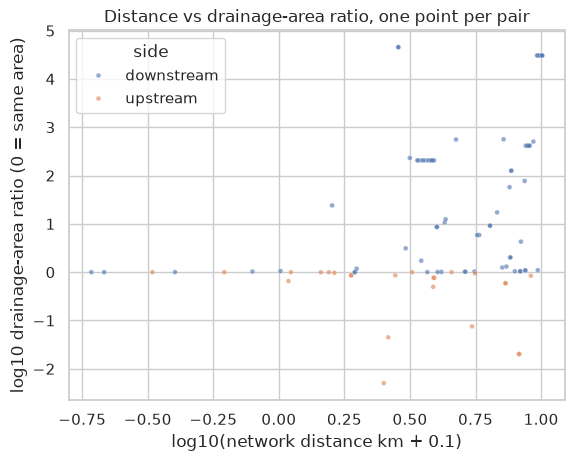

In [15]:
ok = features[features["ratio_status"] == "ok"]
ax = sns.scatterplot(data=ok, x="log10_distance_km", y=np.log10(ok["drainage_area_ratio"]), hue="side", s=12, alpha=0.6)
ax.set(xlabel="log10(network distance km + 0.1)", ylabel="log10 drainage-area ratio (0 = same area)",
       title="Distance vs drainage-area ratio, one point per pair")
plt.show()

## 7. Sampling imbalance

The share of **rows**, **pairs** and **dams** in each category. **How to read it:** a row-weighted model sees `pct_rows`; when that is far above `pct_pairs`, a few heavily sampled pairs dominate. `pct_dams` counts dams with any rows in the category, so it doesn't sum to 100. Nothing is reweighted here.

In [16]:
con.execute("""
    CREATE TEMP TABLE dims AS
    SELECT a.pair, a.AR_ID, a.provider, a.side, a.period, a.season, substr(d.HUC8, 1, 2) AS huc2_region,
           CAST(CAST(floor(a.removal_year / 10) * 10 AS INTEGER) AS VARCHAR) || 's' AS removal_decade
    FROM am a JOIN dam_removal d USING (AR_ID)
""")
n = q("SELECT count(*) AS rows, count(DISTINCT pair) AS pairs, count(DISTINCT AR_ID) AS dams FROM dims").iloc[0]
imbalance = pd.concat([q(f"""
    SELECT '{dim}' AS dimension, CAST({dim} AS VARCHAR) AS category,
           round(100 * count(*) / {n['rows']}, 1) AS pct_rows,
           round(100 * count(DISTINCT pair) / {n['pairs']}, 1) AS pct_pairs,
           round(100 * count(DISTINCT AR_ID) / {n['dams']}, 1) AS pct_dams,
           round(count(*) / count(DISTINCT pair)) AS rows_per_pair
    FROM dims GROUP BY {dim} ORDER BY category""")
    for dim in ["provider", "side", "period", "season", "huc2_region", "removal_decade"]], ignore_index=True)
imbalance

,dimension,category,pct_rows,pct_pairs,pct_dams,rows_per_pair
0,provider,NWIS,38.2,25.6,44.4,783.0
1,provider,STORET,61.8,74.4,87.0,435.0
2,side,downstream,86.2,78.2,81.5,578.0
3,side,upstream,13.8,21.8,38.9,333.0
4,period,post,49.3,100.0,100.0,259.0
5,period,pre,50.7,100.0,100.0,266.0
6,season,fall,25.6,99.2,100.0,136.0
7,season,spring,26.7,95.5,98.1,147.0
8,season,summer,29.1,98.5,100.0,155.0
9,season,winter,18.6,88.0,85.2,111.0


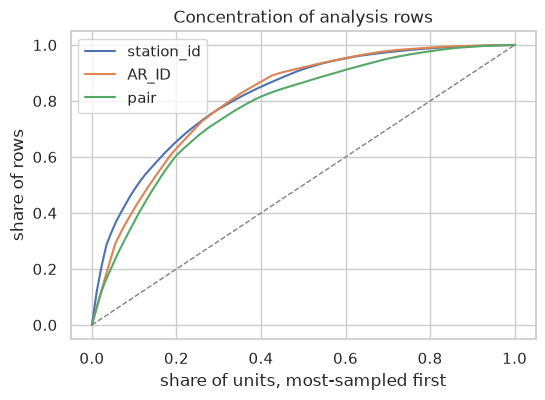

% of analysis rows from the top 1/5/10% of units:


,unit,units,top 1%,top 5%,top 10%
0,station_id,87,11.9,33.0,49.0
1,AR_ID,54,10.2,29.2,39.6
2,pair,133,4.1,22.6,36.2


In [17]:
# Concentration: share of rows from the most-sampled stations, dams and pairs.
rows = []
fig, ax = plt.subplots(figsize=(6, 4))
for unit in ["station_id", "AR_ID", "pair"]:
    counts = q(f"SELECT count(*) AS n FROM am GROUP BY {unit} ORDER BY n DESC")["n"]
    share = counts.cumsum() / counts.sum()
    rows.append({"unit": unit, "units": len(counts),
                 **{f"top {t:.0%}": round(100 * share.iloc[max(1, round(t * len(counts))) - 1], 1) for t in [0.01, 0.05, 0.10]}})
    ax.plot(np.r_[0, np.arange(1, len(counts) + 1) / len(counts)], np.r_[0, share], label=unit)
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax.set(xlabel="share of units, most-sampled first", ylabel="share of rows", title="Concentration of analysis rows")
ax.legend()
plt.show()
print("% of analysis rows from the top 1/5/10% of units:")
pd.DataFrame(rows)

## 8. What each rule would remove (hypothetical; nothing applied)

The flags above as candidate exclusions, in order. `pct_rows_alone` is the share of rows each rule touches on its own. The `remaining_*` columns are what would be left after applying it **together with all rules above it**. Water-quality rules come first; the three covariate rules at the end only matter for models that need climate, land cover or dam height. `name_mismatch` and `direction inconsistent` (section 6) are left out: they are context, not exclusions.

In [18]:
RULES = [
    ("duplicate copy (keep one)", "f_duplicate_copy"),
    ("zero / at limit / suspicious value", "f_bad_value"),
    ("about 1000x station median", "f_x1000"),
    ("inconsistent with a related measurement", "f_inconsistent"),
    (f"outlier |z| > {MAD_THRESHOLD:g}", "f_outlier"),
    (f"series with < {MIN_PAIRS_PER_SERIES} pairs", "small_series"),
    (f"< {RULE_MIN_SAMPLES} samples or < {RULE_MIN_YEARS} years on a side", "thin"),
    (f"< {RULE_MIN_SHARED_MONTHS} shared pre/post months", "few_shared_months"),
    ("another removal inside the window", "overlap"),
    ("saline station", "saline"),
    ("non-riverine station", "non_riverine"),
    (f"snapped > {SNAP_LIMIT_M} m", "far_snap"),
    ("drainage area missing, invalid or truncated", "bad_drainage_area"),
    ("covariates: no climate", "no_climate"),
    ("covariates: no pre-removal land cover", "no_pre_removal_land_cover"),
    ("covariates: no dam height", "no_dam_height"),
]
COUNTS = ("count(*) AS rows, count(DISTINCT measurement_id) AS measurements, count(DISTINCT station_id) AS stations, "
          "count(DISTINCT pair) AS pairs, count(DISTINCT AR_ID) AS dams")
records = [{"rule": "analysis_measurement as built", "pct_rows_alone": 0.0,
            **q(f"SELECT {COUNTS} FROM am_flags").add_prefix("remaining_").iloc[0].to_dict()}]
applied = []
for label, column in RULES:
    applied.append(f"coalesce({column}, FALSE)")
    alone = con.sql(f"SELECT 100 * avg(coalesce({column}, FALSE)::INT) FROM am_flags").fetchone()[0]
    remaining = q(f"SELECT {COUNTS} FROM am_flags WHERE NOT ({' OR '.join(applied)})").add_prefix("remaining_")
    records.append({"rule": label, "pct_rows_alone": round(alone, 2), **remaining.iloc[0].to_dict()})
rule_impact = pd.DataFrame(records)
save(rule_impact, "rule_impact.csv")
rule_impact

,rule,pct_rows_alone,remaining_rows,remaining_measurements,remaining_stations,remaining_pairs,remaining_dams
0,analysis_measurement as built,0.00,69747,46236,87,133,54
1,duplicate copy (keep one),7.91,64228,42953,86,132,54
2,zero / at limit / suspicious value,0.14,64129,42855,86,132,54
3,about 1000x station median,0.01,64126,42853,86,132,54
4,inconsistent with a related measurement,2.53,62359,41114,86,132,54
5,outlier |z| > 5,0.44,62075,40904,86,132,54
6,series with < 20 pairs,5.83,58378,38081,84,130,54
7,< 6 samples or < 2 years on a side,0.99,57754,37789,77,121,52
8,< 3 shared pre/post months,0.69,57606,37651,75,119,51
9,another removal inside the window,81.05,10197,10197,30,30,20


### Decisions for the model-specific stage

Use the table above to decide:

1. **Duplicates** (section 2): keep one copy? Collapse same-day readings to one per day, or per depth?
2. **Values and outliers** (sections 3–4): which flags become exclusions, and at what robust-z threshold?
3. **What belongs** (section 5): which station rules to apply; how to handle overlapping removals (exclude, nearest dam only, or keep and cluster by station); the minimum-data and shared-month rules; dropping small series.
4. **Features** (section 6): use log distance and the drainage-area ratio, and treat upstream stations that were possibly in the former reservoir as treated sites rather than controls?
5. **Imbalance** (section 7): row-, pair- or dam-level weighting or aggregation, separately for the mixed-effects model and XGBoost.

## 9. Alternative exposure rules

Three ways to connect measurements to removals, compared on the same data (none is adopted here):

- **A. All links** (as built): every measurement is used once per eligible dam linked to its station.
- **B. Nearest upstream removal**: each measurement at a *downstream* station is kept once, for the eligible removed dam with the shortest network distance upstream of it. Upstream-side rows are left out, because "nearest upstream dam" doesn't apply to them.
- **C. No competing removals**: pairs with another removal inside their window are dropped (the `overlap` flag of section 5).

**Assumptions and limits of B:** "eligible" means the pair is in `analysis_measurement`. Distance is the `network_distance_km` of the dam-station link. Only removals in `dam_removal` are known: dams still standing between the station and the removal aren't in the data. B ranks dams by distance only, not by removal year. The reliability table below shows how often the choice is clear-cut.

In [19]:
con.execute("""
    CREATE TEMP TABLE ranked AS
    SELECT measurement_id, AR_ID, pair, station_id, series, network_distance_km,
           row_number() OVER w AS rank, count(*) OVER (PARTITION BY measurement_id) AS candidates,
           lead(network_distance_km) OVER w AS next_km
    FROM am WHERE side = 'downstream'
    WINDOW w AS (PARTITION BY measurement_id ORDER BY network_distance_km NULLS LAST, AR_ID)
""")
exposure_rules = au.counts_table(con, {
    "A. all links": "SELECT * FROM am",
    "B. nearest upstream removal (downstream stations)":
        "SELECT a.* FROM am a JOIN ranked r ON r.measurement_id = a.measurement_id AND r.AR_ID = a.AR_ID WHERE r.rank = 1",
    "C. exclude pairs with competing removals": "SELECT a.* FROM am a JOIN pair_overlap o USING (pair) WHERE NOT o.overlap",
})
exposure_rules["rows_per_measurement"] = (exposure_rules["rows"] / exposure_rules["measurements"]).round(2)
save(exposure_rules, "exposure_rules.csv")
exposure_rules

,stage,rows,measurements,stations,dams,pairs,series,rows_per_measurement
0,A. all links,69747,46236,87,54,133,15,1.51
1,B. nearest upstream removal (downstream stations),36957,36957,61,36,81,15,1.00
2,C. exclude pairs with competing removals,13214,13214,39,23,39,15,1.00


In [20]:
# How clear-cut is rule B? One row per downstream measurement.
reliability = q("""
    SELECT CASE WHEN network_distance_km IS NULL THEN 'nearest distance unknown'
                WHEN candidates = 1 THEN 'only one upstream removal'
                WHEN next_km = network_distance_km THEN 'tie with another removal'
                WHEN next_km < 2 * network_distance_km THEN 'next removal < 2x as far'
                ELSE 'next removal >= 2x as far' END AS assignment,
           count(*) AS measurements, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct
    FROM ranked WHERE rank = 1 GROUP BY 1 ORDER BY measurements DESC
""")
upstream_only = con.sql("""SELECT count(DISTINCT measurement_id) FROM am WHERE measurement_id NOT IN
                           (SELECT measurement_id FROM ranked)""").fetchone()[0]
varies = con.sql("""SELECT count(*) FROM (SELECT station_id FROM ranked WHERE rank = 1
                    GROUP BY station_id HAVING count(DISTINCT AR_ID) > 1)""").fetchone()[0]
print(f"Measurements only at upstream-side stations (not assignable under B): {upstream_only:,}")
print(f"Stations whose nearest dam differs by series (eligibility differs by series): {varies:,}")
save(q("SELECT measurement_id, AR_ID, network_distance_km, candidates, next_km FROM ranked WHERE rank = 1"),
     "exposure_nearest_upstream.parquet")
reliability

Measurements only at upstream-side stations (not assignable under B): 9,279
Stations whose nearest dam differs by series (eligibility differs by series): 17


,assignment,measurements,pct
0,only one upstream removal,23103,62.5
1,next removal < 2x as far,8464,22.9
2,next removal >= 2x as far,5390,14.6


## 10. Daily aggregation (derived; originals unchanged)

One row per station × series × day, keeping apart readings that shouldn't be pooled: different **depth** (rounded to 0.1 m), **sample type** (`activity_type`) and **analytical method** (from `wq_measurement_raw`). The value is the median; `n_raw`, min and max are kept. Censoring is carried as `any_censored` / `all_censored`. A group mixing censored and measured values gets a median that includes a half-detection-limit value, and is counted below.

**How to read it:** `pct_fewer_rows` is the reduction. `split_by_depth_type_method` counts the extra rows kept because readings on the same day differed in depth, type or method.

In [21]:
method_field = "ResultAnalyticalMethod/MethodIdentifier"
if "wq_measurement_raw" in HAS and method_field in con.sql("SELECT * FROM wq_measurement_raw LIMIT 0").columns:
    con.execute(f"""CREATE TEMP TABLE method AS SELECT CAST(measurement_id AS BIGINT) AS measurement_id,
                    any_value("{method_field}") AS method_id FROM wq_measurement_raw GROUP BY 1""")
else:
    print("No method field available: days are split by depth and sample type only.")
    con.execute("CREATE TEMP TABLE method AS SELECT measurement_id, NULL::VARCHAR AS method_id FROM m")
con.execute("""
    CREATE TEMP TABLE daily_key AS
    SELECT m.measurement_id, m.station_id, m.parameter_std, m.sample_fraction_std, m.series, m.sample_date,
           round(m.depth_m, 1) AS depth_m, m.activity_type, x.method_id
    FROM m LEFT JOIN method x USING (measurement_id)
""")
con.execute("""
    CREATE TEMP TABLE daily AS
    SELECT k.station_id, k.parameter_std, k.sample_fraction_std, k.series, k.sample_date, k.depth_m,
           k.activity_type, k.method_id, count(*) AS n_raw,
           median(m.result_value_std) AS value_median, min(m.result_value_std) AS value_min,
           max(m.result_value_std) AS value_max,
           bool_or(m.is_censored) AS any_censored, bool_and(m.is_censored) AS all_censored,
           min(k.measurement_id) AS first_measurement_id
    FROM daily_key k JOIN m USING (measurement_id) GROUP BY ALL
""")
save(q("SELECT * FROM daily"), "daily_measurements.parquet")
daily_compare = q("""
    WITH simple AS (SELECT series, count(DISTINCT (station_id, sample_date)) AS station_days FROM m GROUP BY series)
    SELECT d.series, sum(d.n_raw) AS raw_rows, count(*) AS daily_rows,
           count(*) - any_value(s.station_days) AS split_by_depth_type_method,
           round(100 * (1 - count(*) / sum(d.n_raw)), 1) AS pct_fewer_rows,
           count(*) FILTER (WHERE d.any_censored AND NOT d.all_censored) AS mixed_censoring_days
    FROM daily d JOIN simple s USING (series) GROUP BY d.series ORDER BY raw_rows DESC
""")
daily_compare

,series,raw_rows,daily_rows,split_by_depth_type_method,pct_fewer_rows,mixed_censoring_days
0,water_temp,67267.0,51046,982,24.1,0
1,ph,61394.0,57105,11221,7.0,0
2,specific_conductance,58990.0,53664,10135,9.0,0
3,dissolved_oxygen,48224.0,44554,983,7.6,0
4,phosphorus (Total),32895.0,31610,72,3.9,9
5,orthophosphate (Dissolved),22491.0,21515,90,4.3,16
6,tds,21427.0,21302,9,0.6,1
7,orthophosphate (Total),18027.0,17957,0,0.4,1
8,turbidity,17294.0,16156,455,6.6,0
9,phosphorus (Dissolved),15237.0,14960,60,1.8,5


In [22]:
def top_shares(counts):
    """% of rows from the top 1/5/10% of units (counts: rows per unit)."""
    share = counts.sort_values(ascending=False).cumsum() / counts.sum()
    return {f"top {t:.0%}": round(float(100 * share.iloc[max(1, round(t * len(counts))) - 1]), 1) for t in [0.01, 0.05, 0.10]}


# Concentration of the analysis data by station: distinct measurements vs daily groups.
analysis_ids = "SELECT DISTINCT measurement_id FROM am"
raw_counts = q(f"SELECT station_id, count(*) AS n FROM m WHERE measurement_id IN ({analysis_ids}) GROUP BY 1")["n"]
daily_counts = q(f"""SELECT station_id, count(DISTINCT (series, sample_date, depth_m, activity_type, method_id)) AS n
                     FROM daily_key WHERE measurement_id IN ({analysis_ids}) GROUP BY 1""")["n"]
pd.DataFrame([{"data": "measurements (raw)", "rows": raw_counts.sum(), **top_shares(raw_counts)},
              {"data": "daily groups", "rows": daily_counts.sum(), **top_shares(daily_counts)}])

,data,rows,top 1%,top 5%,top 10%
0,measurements (raw),46236,8.3,21.5,39.6
1,daily groups,43734,8.8,22.3,39.9


## 11. Refined site and duplicate diagnostics

**Co-located stations.** Proximity alone isn't evidence of a duplicate: two stations 100 m apart can genuinely read pH 7.2 on the same day. Each pair of stations on the same reach within `COLOCATED_M` is classified by **how consistently** they agree. The comparison uses daily medians (so depth profiles don't multiply matches), on every day and series both stations sampled:

- `likely duplicate`: at least `COLOC_MIN_DATES` shared days, and on at least `COLOC_MIN_AGREE` of them **every** shared series is identical;
- `possible duplicate`: identical on at least half of the shared observations;
- `independent`: they sample the same days but disagree;
- `no shared days`.

Only the identical values of `likely duplicate` pairs get the refined flag: the non-NWIS copy, otherwise the second station's.

In [23]:
COLOC_MIN_DATES, COLOC_MIN_AGREE = 5, 0.8
con.execute(f"""
    CREATE TEMP TABLE coloc_pairs AS
    SELECT a.station_id AS station_a, b.station_id AS station_b, a.organization_id AS org_a,
           b.organization_id AS org_b, {hav} AS distance_m
    FROM wq_station a JOIN wq_station b ON a.NHDPlusID = b.NHDPlusID AND a.station_id < b.station_id AND {hav} <= {COLOCATED_M}
""")
con.execute(f"""
    CREATE TEMP TABLE coloc_evidence AS
    WITH d AS (SELECT station_id, series, sample_date, median(result_value_std) AS v FROM m GROUP BY ALL),
    obs AS (SELECT c.station_a, c.station_b, x.series, x.sample_date, x.v = y.v AS same
            FROM coloc_pairs c JOIN d x ON x.station_id = c.station_a
            JOIN d y ON y.station_id = c.station_b AND y.series = x.series AND y.sample_date = x.sample_date),
    by_day AS (SELECT station_a, station_b, sample_date, bool_and(same) AS all_same FROM obs GROUP BY ALL),
    o AS (SELECT station_a, station_b, count(*) AS shared_obs, sum(same::INT) AS identical_obs,
                 count(DISTINCT series) AS shared_series FROM obs GROUP BY ALL),
    b AS (SELECT station_a, station_b, count(*) AS shared_days, sum(all_same::INT) AS identical_days FROM by_day GROUP BY ALL)
    SELECT c.*, coalesce(o.shared_obs, 0) AS shared_obs, coalesce(o.identical_obs, 0) AS identical_obs,
           coalesce(o.shared_series, 0) AS shared_series, coalesce(b.shared_days, 0) AS shared_days,
           coalesce(b.identical_days, 0) AS identical_days,
           CASE WHEN coalesce(b.shared_days, 0) = 0 THEN 'no shared days'
                WHEN b.shared_days >= {COLOC_MIN_DATES} AND b.identical_days >= {COLOC_MIN_AGREE} * b.shared_days
                    THEN 'likely duplicate'
                WHEN o.identical_obs >= 0.5 * o.shared_obs THEN 'possible duplicate'
                ELSE 'independent' END AS verdict
    FROM coloc_pairs c LEFT JOIN o USING (station_a, station_b) LEFT JOIN b USING (station_a, station_b)
""")
con.execute("""
    CREATE TEMP TABLE duplicate_copies_refined AS
    SELECT DISTINCT CASE WHEN x.provider = 'NWIS' AND y.provider <> 'NWIS' THEN y.measurement_id
                         WHEN y.provider = 'NWIS' AND x.provider <> 'NWIS' THEN x.measurement_id
                         ELSE y.measurement_id END AS measurement_id
    FROM coloc_evidence e
    JOIN m x ON x.station_id = e.station_a
    JOIN m y ON y.station_id = e.station_b AND y.sample_date = x.sample_date AND y.series = x.series
         AND y.result_value_std = x.result_value_std
    WHERE e.verdict = 'likely duplicate'
""")
save(q("SELECT * FROM coloc_evidence"), "colocated_station_pairs.csv")
coloc_summary = q("""
    SELECT verdict, count(*) AS station_pairs, count(*) FILTER (WHERE org_a <> org_b) AS different_orgs,
           sum(shared_obs) AS shared_obs, sum(identical_obs) AS identical_obs
    FROM coloc_evidence GROUP BY 1 ORDER BY station_pairs DESC
""")
old_copies = con.sql("SELECT count(DISTINCT measurement_id) FROM duplicate_copies WHERE reason = 'co-located station copy'").fetchone()[0]
new_copies = con.sql("SELECT count(*) FROM duplicate_copies_refined").fetchone()[0]
print(f"Co-located copies flagged: {old_copies:,} by proximity + identical value (section 2) -> {new_copies:,} refined")
coloc_summary

Co-located copies flagged: 15,427 by proximity + identical value (section 2) -> 419 refined


,verdict,station_pairs,different_orgs,shared_obs,identical_obs
0,no shared days,9221,5052,0.0,0.0
1,independent,583,55,41173.0,8867.0
2,possible duplicate,45,35,3291.0,1874.0
3,likely duplicate,7,7,320.0,319.0


**Non-riverine stations, refined.** The section 5 heuristic flagged any name containing a water-body word, which caught stream sites such as "MAXWELL POND-OUTLET" or "KNOX MARSH RD BRIDGE". The refined rule still flags a water-body word, but **not** when the name also places the site on a stream or crossing (inlet, outlet, brook, creek, river, tributary, below/above, dam, bridge, road, route, highway...). A canal, connector or coastline reach is flagged either way. Saline and extreme values stay as flags only, not exclusions.

In [24]:
RIVERINE_CONTEXT = (r"\b(?:inlet|outlet|outflow|brook|creek|cr|crk|river|riv|stream|run|kill|trib\w*|branch|br|"
                    r"below|blw|bl|above|abv|ab|ds|us|dam|spillway|bridge|road|rd|rte|route|hwy|highway|street|st|ave)\b")
names = stations["station_name"].fillna("").str.lower()
water_word = names.str.contains(WATER_BODY, regex=True)
stations["non_riverine_refined"] = ((water_word & ~names.str.contains(RIVERINE_CONTEXT, regex=True))
                                    | stations["feature_type"].isin([336, 334, 566]))
changed = stations[stations["non_riverine"] != stations["non_riverine_refined"]]
print(f"Non-riverine stations: {int(stations['non_riverine'].sum())} (section 5) -> "
      f"{int(stations['non_riverine_refined'].sum())} refined; {len(changed)} changed")
display(stations[stations["non_riverine_refined"]][["station_id", "station_name", "reach_name", "sc_median"]].head(10))
print("No longer flagged (examples):")
changed[["station_id", "station_name", "reach_name"]].head(10)

Non-riverine stations: 5 (section 5) -> 0 refined; 5 changed


,station_id,station_name,reach_name,sc_median


No longer flagged (examples):


,station_id,station_name,reach_name
1,11113300-EASGTMO,EASTMAN POND-EASTMAN BROOK OUTLET,Eastman Brook
2,11113300-EASGTM2,EASTMAN POND-MILL POND BROOK,Stony Brook
3,11113300-EASGTMSB,EASTMAN POND-STONEY BROOK,Stony Brook
5,11113300-STOGTMO,STOCKER POND-OUTLET,Stocker Brook
73,11NPSWRD_WQX-ROMO_JB_LOUISO,OUTLET STREAM FROM LAKE LOUISE,NaN


**Stations snapped more than `SNAP_LIMIT_M` from a stream.** Reported coordinates (`latitude`/`longitude`, in the station's reported datum) next to the snapped point on the NHDPlus reach (the `wq_station` geometry, EPSG:4326). **How to read it:** a large snap plus `name_matches = False` suggests the wrong reach; a large snap with a matching name more likely means imprecise reported coordinates on the right river.

In [25]:
import geopandas as gpd

snapped = gpd.read_parquet(WAREHOUSE / "wq_station.parquet", columns=["station_id", "geometry"])
snapped["snapped_lat"], snapped["snapped_lon"] = snapped.geometry.y, snapped.geometry.x
links = q("""SELECT station_id, string_agg(DISTINCT AR_ID, ', ') AS dams, count(DISTINCT pair) AS pairs,
                    sum(rows) AS analysis_rows FROM pairs GROUP BY 1""")
far = (stations[stations["far_snap"]][["station_id", "station_name", "snap_distance_m", "reach_name", "name_mismatch"]]
       .merge(q("SELECT station_id, organization_id, latitude, longitude, horizontal_datum FROM wq_station"), on="station_id")
       .merge(snapped[["station_id", "snapped_lat", "snapped_lon"]], on="station_id", how="left")
       .merge(links, on="station_id", how="left")
       .assign(name_matches=lambda d: ~d["name_mismatch"])
       .drop(columns="name_mismatch")
       .sort_values("snap_distance_m", ascending=False))
far["snap_distance_m"] = far["snap_distance_m"].round(0)
save(far, "far_snapped_stations.csv")
print(f"{len(far)} stations; missing reported coordinates: {far[['latitude', 'longitude']].isna().any(axis=1).sum()}, "
      f"missing snapped point: {far[['snapped_lat', 'snapped_lon']].isna().any(axis=1).sum()}")
far

5 stations; missing reported coordinates: 0, missing snapped point: 0


,station_id,station_name,snap_distance_m,reach_name,organization_id,latitude,longitude,horizontal_datum,snapped_lat,snapped_lon,dams,pairs,analysis_rows,name_matches
1,21PA_WQX-MAR11,Susquehanna River Marietta Transect 11,766.0,Susquehanna River,21PA_WQX,40.0314,-76.5100,NAD83,40.025802,-76.515240,"PA-319, PA-338, PA-286",3,677.0,True
2,21PA_WQX-MAR10,Susquehanna River Marietta Transect 10,736.0,Susquehanna River,21PA_WQX,40.0314,-76.5106,NAD83,40.026021,-76.515635,"PA-286, PA-319",2,442.0,True
4,21PA_WQX-MAR1,Susquehanna River Marietta Transect 1,580.0,Susquehanna River,21PA_WQX,40.0264,-76.5269,NAD83,40.030372,-76.522486,"PA-333, PA-319, PA-286",3,688.0,True
0,21PA_WQX-MAR9,Susquehanna River Marietta Transect 9,569.0,Susquehanna River,21PA_WQX,40.0306,-76.5125,NAD83,40.026440,-76.516393,"PA-286, PA-338, PA-319",3,2172.0,True
3,21PA_WQX-MAR2,Susquehanna River Marietta Transect 2,552.0,Susquehanna River,21PA_WQX,40.0264,-76.5264,NAD83,40.030182,-76.522197,"PA-286, PA-319, PA-333",3,669.0,True


## 12. Map of far-snapped stations

Blue: the reported location. Red: the snapped point on the stream. Dashed line: the snap. Each station's snapped reach is drawn in light blue where the `streams` table has it. Click a marker for details. Saved as `far_snapped_stations_map.html`.

In [26]:
import folium

reaches = None
try:  # only the snapped reaches of these stations, read with a Parquet filter
    reach_ids = q(f"SELECT NHDPlusID FROM wq_station WHERE station_id IN ({sql_list(far['station_id'])})")["NHDPlusID"]
    reaches = gpd.read_parquet(WAREHOUSE / "streams.parquet", columns=["nhdplus_id", "gnis_name", "geometry"],
                               filters=[("nhdplus_id", "in", [int(i) for i in reach_ids])])
except Exception as error:
    print("Reaches not drawn:", error)

far_map = folium.Map(tiles="OpenStreetMap")
layers = {name: folium.FeatureGroup(name=name) for name in
          ["Reported location", "Snapped location", "Snap line", "Snapped reach"]}
points = []
for r in far.itertuples():
    popup_html = (
        f"<b>{r.station_id}</b><br>{r.station_name}<br>Organization: {r.organization_id}<br>"
        f"Snap distance: {r.snap_distance_m:,.0f} m<br>Reach: {r.reach_name}<br>"
        f"Reported: {r.latitude:.5f}, {r.longitude:.5f} ({r.horizontal_datum})<br>"
        f"Snapped: {r.snapped_lat:.5f}, {r.snapped_lon:.5f}<br>Dams: {r.dams} ({r.pairs} pairs)")
    reported = None if pd.isna(r.latitude) or pd.isna(r.longitude) else [r.latitude, r.longitude]
    on_stream = None if pd.isna(r.snapped_lat) else [r.snapped_lat, r.snapped_lon]
    if reported:
        folium.CircleMarker(reported, radius=6, color="#1f77b4", fill=True, fill_opacity=0.9,
                            popup=folium.Popup(popup_html, max_width=350), tooltip=r.station_id).add_to(layers["Reported location"])
    if on_stream:
        folium.CircleMarker(on_stream, radius=5, color="#d62728", fill=True, fill_opacity=0.9,
                            popup=folium.Popup(popup_html, max_width=350), tooltip=f"{r.station_id} (snapped)").add_to(layers["Snapped location"])
    if reported and on_stream:
        folium.PolyLine([reported, on_stream], color="gray", weight=2, dash_array="6").add_to(layers["Snap line"])
    points += [p for p in (reported, on_stream) if p]
if reaches is not None and len(reaches):
    folium.GeoJson(reaches, style_function=lambda _: {"color": "#6baed6", "weight": 3},
                   tooltip=folium.GeoJsonTooltip(["gnis_name"])).add_to(layers["Snapped reach"])
for layer in layers.values():
    layer.add_to(far_map)
folium.LayerControl(collapsed=False).add_to(far_map)
far_map.get_root().html.add_child(folium.Element("""
    <div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white; padding: 8px 10px;
                border: 1px solid #999; font-size: 13px;">
    <span style="color:#1f77b4">&#9679;</span> Reported location<br>
    <span style="color:#d62728">&#9679;</span> Snapped location<br>
    <span style="color:gray">- - -</span> Snap line<br>
    <span style="color:#6baed6">&#9473;</span> Snapped reach</div>"""))
if points:
    far_map.fit_bounds(points, padding=(30, 30))
if SAVE_OUTPUTS:
    far_map.save(str(OUTPUT_DIR / "far_snapped_stations_map.html"))

display(far_map)

## 13. Snapping audit - Dams

`snap_features.py` puts each dam and station on the **geometrically nearest** NHDPlus flowline. It doesn't check the flowline's type, name or size, and sets no distance limit. Near a confluence, a dam on a main river can land on a small tributary, or the reverse, **with a small snap distance**. A wrong dam reach is the costliest error: it moves the dam's position on the network, so every linked station can get the wrong side, distance and drainage-area ratio.

For each analysis dam, this lists every flowline within `DAM_RADIUS_M` of the dam's **reported** location. It reads them with the spatial index of the NHDPlus files already on disk; no network is rebuilt. Then it checks:

- `name`: does the snapped reach's GNIS name match the dam's `River`?
- `named_alternative`: if not, is there a nearby reach whose name *does* match?
- `non_stream`: is the snapped reach a canal, connector, coastline or pipeline, rather than a stream or a river's path through a lake?
- `size_ambiguity`: is a reach about as close (within the snap distance + 50 m) but of very different size (drainage area ≥ 5× different)? That is typical of a confluence.
- `far`: was the dam moved more than `DAM_FAR_M`?

**Verdict:** `likely wrong` = a non-stream reach, or a name mismatch with a correctly named reach nearby. `check` = size ambiguity, a far snap, or a name mismatch with no named alternative. `ok` otherwise (`no name to check` when the dam has no `River`, or the reach has no name). The first run reads the packages (cached afterwards).

In [27]:
import pyogrio
from pyproj import CRS, Transformer

DAM_RADIUS_M = 500     # search radius around each dam's reported location
DAM_FAR_M = 150        # dams are usually reported on the stream; farther snaps are checked
STREAM_FTYPES = [460, 558]   # StreamRiver, ArtificialPath
NHDPLUS_DIR = DATA_ROOT / "data" / "processed" / "nhdplus_extracted"

dam_check = q("""
    SELECT d.AR_ID, d.Dam_Name, d.River, d.State, d.HUC8, d.Latitude, d.Longitude, d.Dam_Height_ft,
           d.NHDPlusID AS snapped_reach, d.snap_distance_m, r.gnis_name AS reach_name, r.feature_type,
           count(DISTINCT p.pair) AS pairs, count(DISTINCT p.station_id) AS stations, sum(p.rows) AS analysis_rows
    FROM dam_removal d JOIN pairs p USING (AR_ID) LEFT JOIN streams r ON r.nhdplus_id = d.NHDPlusID
    GROUP BY ALL
""")
dam_points = gpd.read_parquet(WAREHOUSE / "dam_removal.parquet", columns=["AR_ID", "geometry"])
dam_check = dam_check.merge(dam_points.assign(snapped_lat=dam_points.geometry.y, snapped_lon=dam_points.geometry.x)
                            [["AR_ID", "snapped_lat", "snapped_lon"]], on="AR_ID", how="left")

candidate_cache = OUTPUT_DIR / "dam_candidate_reaches.parquet"
if candidate_cache.exists():
    candidates = gpd.read_parquet(candidate_cache)
else:
    frames, packages = [], set()
    for huc8, group in dam_check.groupby("HUC8"):
        try:
            package = find_huc8_geodatabase(NHDPLUS_DIR, huc8)
        except FileNotFoundError:
            continue
        packages.add(package)
        info = pyogrio.read_info(package, layer="NHDFlowline")
        fields = {str(f).lower(): str(f) for f in info["fields"]}
        to_layer = Transformer.from_crs("EPSG:4326", info["crs"], always_xy=True)
        pad = DAM_RADIUS_M / 111_000 * 2 if CRS(info["crs"]).is_geographic else DAM_RADIUS_M * 1.5
        for d in group.itertuples():
            x, y = to_layer.transform(d.Longitude, d.Latitude)
            near = pyogrio.read_dataframe(package, layer="NHDFlowline", bbox=(x - pad, y - pad, x + pad, y + pad),
                                          columns=[fields["nhdplusid"], fields["gnis_name"], fields["ftype"]])
            near = near.rename(columns={fields["nhdplusid"]: "nhdplusid", fields["gnis_name"]: "gnis_name",
                                        fields["ftype"]: "ftype"})
            frames.append(near.to_crs("EPSG:4326").assign(AR_ID=d.AR_ID))
    candidates = gpd.GeoDataFrame(pd.concat(frames, ignore_index=True), crs="EPSG:4326")
    candidates["nhdplusid"] = pd.to_numeric(candidates["nhdplusid"]).astype("int64")
    # Distance from the reported dam location, in that dam's UTM zone.
    candidates = candidates.merge(dam_check[["AR_ID", "Latitude", "Longitude"]], on="AR_ID")
    candidates["utm"] = (np.where(candidates["Latitude"] >= 0, 32600, 32700)
                         + ((candidates["Longitude"] + 180) // 6 + 1).astype(int))
    candidates["distance_m"] = np.nan
    for epsg, g in candidates.groupby("utm"):
        reported = gpd.GeoSeries(gpd.points_from_xy(g["Longitude"], g["Latitude"]), crs=4326, index=g.index).to_crs(epsg)
        candidates.loc[g.index, "distance_m"] = g.geometry.to_crs(epsg).distance(reported)
    candidates = candidates[candidates["distance_m"] <= DAM_RADIUS_M].drop(columns=["Latitude", "Longitude", "utm"])
    sizes, _ = au.read_vaa(sorted(packages), candidates["nhdplusid"], ["NHDPlusID", "TotDASqKm"], progress=True)
    candidates = candidates.merge(sizes[["nhdplusid", "totdasqkm"]].astype({"nhdplusid": "int64"}), on="nhdplusid", how="left")
    if SAVE_OUTPUTS:
        candidates.to_parquet(candidate_cache, index=False)
print(f"{len(candidates):,} candidate reaches within {DAM_RADIUS_M} m of {candidates['AR_ID'].nunique()} of "
      f"{len(dam_check)} analysis dams")

2,665 candidate reaches within 500 m of 338 of 54 analysis dams


In [28]:
def check_dam(d, near):
    snapped = near[near["nhdplusid"] == d.snapped_reach]
    snapped_area = snapped["totdasqkm"].iloc[0] if len(snapped) else np.nan
    others = near[near["nhdplusid"] != d.snapped_reach]
    match = au.name_matches(d.River, d.reach_name)
    named = others[[au.name_matches(d.River, n) is True for n in others["gnis_name"]]]
    close = others[others["distance_m"] <= d.snap_distance_m + 50]
    ratio = close["totdasqkm"] / snapped_area
    row = {
        "name": {True: "match", False: "mismatch"}.get(match, "no name to check"),
        "named_alternative_m": named["distance_m"].min() if match is False and len(named) else np.nan,
        "named_alternative_reach": named.sort_values("distance_m")["gnis_name"].iloc[0] if match is False and len(named) else None,
        "non_stream": not pd.isna(d.feature_type) and int(d.feature_type) not in STREAM_FTYPES,
        "size_ambiguity": bool(((ratio >= 5) | (ratio <= 0.2)).any()),
        "far": d.snap_distance_m > DAM_FAR_M,
        "snapped_area_km2": snapped_area,
    }
    if row["non_stream"] or not pd.isna(row["named_alternative_m"]):
        row["verdict"] = "likely wrong"
    elif row["size_ambiguity"] or row["far"] or row["name"] == "mismatch":
        row["verdict"] = "check"
    else:
        row["verdict"] = "ok" if row["name"] == "match" else "ok (no name to check)"
    return row


by_dam = dict(tuple(candidates.groupby("AR_ID")))
empty = candidates.iloc[0:0]
dam_check = dam_check.join(pd.DataFrame([check_dam(d, by_dam.get(d.AR_ID, empty)) for d in dam_check.itertuples()],
                                        index=dam_check.index))
save(dam_check, "dam_snap_check.csv")
order = ["likely wrong", "check", "ok", "ok (no name to check)"]
display(dam_check.groupby("verdict").agg(dams=("AR_ID", "size"), pairs=("pairs", "sum"), stations=("stations", "sum"),
                                         analysis_rows=("analysis_rows", "sum")).reindex(order).fillna(0).astype(int))
print("Why dams were flagged (a dam can have several reasons):")
display(pd.Series({"non-stream reach": dam_check["non_stream"].sum(),
                   "name mismatch, correctly named reach nearby": dam_check["named_alternative_m"].notna().sum(),
                   "name mismatch, no named alternative": ((dam_check["name"] == "mismatch")
                                                           & dam_check["named_alternative_m"].isna()).sum(),
                   "size ambiguity (confluence)": dam_check["size_ambiguity"].sum(),
                   f"snapped > {DAM_FAR_M} m": dam_check["far"].sum()}).to_frame("dams"))
print("Flagged dams, most analysis rows first:")
dam_check[dam_check["verdict"].isin(["likely wrong", "check"])].sort_values(["verdict", "analysis_rows"], ascending=[False, False])[
    ["AR_ID", "Dam_Name", "River", "reach_name", "named_alternative_reach", "named_alternative_m", "snap_distance_m",
     "size_ambiguity", "verdict", "pairs", "analysis_rows"]].head(25)

,dams,pairs,stations,analysis_rows
verdict,,,,
likely wrong,0,0,0,0
check,8,29,29,13712
ok,39,94,94,45824
ok (no name to check),7,10,10,10211


Why dams were flagged (a dam can have several reasons):


,dams
non-stream reach,0
"name mismatch, correctly named reach nearby",0
"name mismatch, no named alternative",1
size ambiguity (confluence),7
snapped > 150 m,2


Flagged dams, most analysis rows first:


,AR_ID,Dam_Name,River,reach_name,named_alternative_reach,named_alternative_m,snap_distance_m,size_ambiguity,verdict,pairs,analysis_rows
13,PA-286,Heistand Sawmill Dam,Chiques Creek,Chiques Creek,None,NaN,1.292846,True,check,15,7099.0
35,PA-179,Axe Factory Dam,Fishing Creek,Fishing Creek,None,NaN,13.141237,True,check,3,2886.0
25,CO-022,Carriage Hills #2 Dam,Fish Creek,Fish Creek,None,NaN,103.560257,True,check,4,1455.0
29,CT-035,Norton Paper Mill Dam,Jeremy River,NaN,None,NaN,290.699091,True,check,2,1337.0
49,PA-402,Benner Springs Dam,Spring Creek,Spring Creek,None,NaN,6.901892,True,check,1,420.0
10,PA-059,Meisers Mill Dam,West Branch Mahantango Creek,Gebhard Run,None,NaN,11.186342,False,check,1,291.0
18,PA-323,Eckenrode Mills Dam,Chest Creek,Chest Creek,None,NaN,86.616960,True,check,1,144.0
26,CO-004,Glacier #1 Dam,North Fork Big Thompson River,North Fork Big Thompson River,None,NaN,190.021161,True,check,2,80.0


**Map of flagged dams.** Blue: the reported location. Red: the snapped point, with its reach in red. Green: the nearest correctly named reach, if there is one. Gray: other reaches within `DAM_RADIUS_M`. Use the layer control to switch between `likely wrong` and `check` dams. Saved as `dam_snap_check_map.html`.

In [29]:
flagged = dam_check[dam_check["verdict"].isin(["likely wrong", "check"])]
dam_map = folium.Map(tiles="OpenStreetMap")
groups = {v: folium.FeatureGroup(name=f"{v} ({(flagged['verdict'] == v).sum()})") for v in ["likely wrong", "check"]}
points = []
for d in flagged.itertuples():
    layer = groups[d.verdict]
    text = (f"<b>{d.AR_ID}</b> {d.Dam_Name}<br>River: {d.River}<br>Snapped reach: {d.reach_name} "
            f"({d.snap_distance_m:,.0f} m)<br>Named alternative: {d.named_alternative_reach} "
            f"({d.named_alternative_m:,.0f} m)<br>Size ambiguity: {d.size_ambiguity}<br>"
            f"Pairs: {d.pairs}, analysis rows: {d.analysis_rows:,}")
    near = by_dam.get(d.AR_ID, empty)
    for c in near.itertuples():
        snapped_reach = c.nhdplusid == d.snapped_reach
        named = au.name_matches(d.River, c.gnis_name) is True and not snapped_reach
        style = ({"color": "#d62728", "weight": 4} if snapped_reach else
                 {"color": "#2ca02c", "weight": 4} if named else {"color": "#999999", "weight": 2})
        folium.GeoJson(c.geometry.__geo_interface__, style_function=lambda _, s=style: s,
                       tooltip=f"{'(unnamed)' if pd.isna(c.gnis_name) else c.gnis_name} | {c.totdasqkm:,.1f} km2 | {c.distance_m:,.0f} m").add_to(layer)
    folium.CircleMarker([d.Latitude, d.Longitude], radius=7, color="#1f77b4", fill=True, fill_opacity=0.9,
                        popup=folium.Popup(text, max_width=350), tooltip=f"{d.AR_ID} (reported)").add_to(layer)
    if not pd.isna(d.snapped_lat):
        folium.CircleMarker([d.snapped_lat, d.snapped_lon], radius=5, color="#d62728", fill=True, fill_opacity=0.9,
                            popup=folium.Popup(text, max_width=350), tooltip=f"{d.AR_ID} (snapped)").add_to(layer)
        points.append([d.snapped_lat, d.snapped_lon])
    points.append([d.Latitude, d.Longitude])
for layer in groups.values():
    layer.add_to(dam_map)
folium.LayerControl(collapsed=False).add_to(dam_map)
dam_map.get_root().html.add_child(folium.Element("""
    <div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white; padding: 8px 10px;
                border: 1px solid #999; font-size: 13px;">
    <span style="color:#1f77b4">&#9679;</span> Reported dam location<br>
    <span style="color:#d62728">&#9679; &#9473;</span> Snapped point and reach<br>
    <span style="color:#2ca02c">&#9473;</span> Correctly named reach nearby<br>
    <span style="color:#999999">&#9473;</span> Other reaches</div>"""))
if points:
    dam_map.fit_bounds(points, padding=(30, 30))
if SAVE_OUTPUTS:
    dam_map.save(str(OUTPUT_DIR / "dam_snap_check_map.html"))
display(dam_map)

## 14. Snapping audit - Stations

Two independent checks for each analysis station:

- **Drainage area.** Many agencies (especially USGS) report a station's drainage area in the WQP station file (`DrainageAreaMeasure`, read from the raw downloads in `data/raw/wqp/stations/`). Compared with the NHDPlus drainage area of the snapped reach, a ratio far from 1 means the wrong reach, **whatever the snap distance**. NHDPlus gives the area at the reach's downstream end, so ratios slightly above 1 are normal: `agrees` is 0.8–1.25, `roughly` is 0.5–2, `mismatch` is outside that.
- **Name.** Only for stations whose name contains a river word (river, creek, brook, run, ...), so coded names like "LE3.2" aren't counted as mismatches.

**Verdict:** `likely wrong` = a drainage-area mismatch, or a non-stream reach. `check` = a name mismatch (named stations only) with a snap over 100 m. The seven stations already confirmed on the map are listed in `CONFIRMED_WRONG`.

In [30]:
CONFIRMED_WRONG = ["11113300-SILHARSB1", "11113300-SILHARL1", "11113300-SILHARL2",
                   "CHESAPEAKEMONITORINGCOOP-CMC.LWQVC.MILL3", "CADWR-1541.00", "MNPCA-S004-561", "WIDNR_WQX-10040927"]
AREA_TO_KM2 = {"sqmi": 2.58999, "mi2": 2.58999, "sqkm": 1.0, "km2": 1.0, "acre": 0.00404686, "acres": 0.00404686,
               "ha": 0.01}
RIVER_WORDS = r"\b(?:river|riv|r|creek|cr|crk|ck|brook|bk|run|kill|branch|br|fork|stream|bayou)\b"

station_dir = DATA_ROOT / "data" / "raw" / "wqp" / "stations"
wanted = ["MonitoringLocationIdentifier", "DrainageAreaMeasure/MeasureValue", "DrainageAreaMeasure/MeasureUnitCode",
          "ContributingDrainageAreaMeasure/MeasureValue", "ContributingDrainageAreaMeasure/MeasureUnitCode"]
huc8s = q("SELECT DISTINCT huc8 FROM wq_station WHERE station_id IN (SELECT station_id FROM pairs)")["huc8"]
raw = [pd.read_csv(station_dir / f"{h}.csv", usecols=lambda c: c in wanted, dtype=str)
       for h in huc8s if (station_dir / f"{h}.csv").exists()]
reported = (pd.concat(raw, ignore_index=True) if raw else pd.DataFrame()).reindex(columns=wanted) \
    .drop_duplicates("MonitoringLocationIdentifier")


def to_km2(value, unit):
    factor = unit.fillna("").str.lower().str.replace(r"[\s.]", "", regex=True).map(AREA_TO_KM2)
    return pd.to_numeric(value, errors="coerce") * factor


reported["reported_area_km2"] = to_km2(reported["DrainageAreaMeasure/MeasureValue"],
                                       reported["DrainageAreaMeasure/MeasureUnitCode"]).fillna(
    to_km2(reported["ContributingDrainageAreaMeasure/MeasureValue"],
           reported["ContributingDrainageAreaMeasure/MeasureUnitCode"]))
station_check = (stations[["station_id", "station_name", "snap_distance_m", "reach_name", "feature_type"]]
                 .merge(q("SELECT station_id, NHDPlusID, organization_id FROM wq_station"), on="station_id")
                 .merge(vaa[["nhdplusid", "totdasqkm"]].rename(columns={"nhdplusid": "NHDPlusID", "totdasqkm": "reach_area_km2"}),
                        on="NHDPlusID", how="left")
                 .merge(reported[["MonitoringLocationIdentifier", "reported_area_km2"]]
                        .rename(columns={"MonitoringLocationIdentifier": "station_id"}), on="station_id", how="left")
                 .merge(links[["station_id", "dams", "pairs", "analysis_rows"]], on="station_id", how="left"))
ratio = station_check["reach_area_km2"].where(station_check["reach_area_km2"] > 0) / \
    station_check["reported_area_km2"].where(station_check["reported_area_km2"] > 0)
station_check["area_ratio"] = ratio.round(2)
station_check["area"] = np.select([ratio.isna(), ratio.between(0.8, 1.25), ratio.between(0.5, 2)],
                                  ["not reported", "agrees", "roughly"], "mismatch")
named = station_check["station_name"].fillna("").str.lower().str.contains(RIVER_WORDS, regex=True)
station_check["name"] = np.where(~named, "no river name in station name",
                                 np.where([au.name_matches(s, r) is False for s, r in
                                           zip(station_check["station_name"], station_check["reach_name"])],
                                          "mismatch", "match or unnamed reach"))
station_check["non_stream"] = station_check["feature_type"].notna() & ~station_check["feature_type"].isin(STREAM_FTYPES)
station_check["verdict"] = np.select(
    [station_check["station_id"].isin(CONFIRMED_WRONG),
     (station_check["area"] == "mismatch") | station_check["non_stream"],
     (station_check["name"] == "mismatch") & (station_check["snap_distance_m"] > 100)],
    ["confirmed wrong (map)", "likely wrong", "check"], "ok")
save(station_check, "station_snap_check.csv")
display(pd.crosstab(station_check["area"], station_check["name"], margins=True))
station_check.groupby("verdict").agg(stations=("station_id", "size"), pairs=("pairs", "sum"),
                                     analysis_rows=("analysis_rows", "sum"))

name,match or unnamed reach,mismatch,no river name in station name,All
area,,,,
agrees,19,0,0,19
not reported,41,4,21,66
roughly,2,0,0,2
All,62,4,21,87


,stations,pairs,analysis_rows
verdict,,,
ok,87,133,69747.0


In [31]:
print("Stations whose reported drainage area disagrees with the snapped reach, most analysis rows first:")
station_check[station_check["verdict"] == "likely wrong"].sort_values("analysis_rows", ascending=False)[
    ["station_id", "station_name", "reach_name", "reported_area_km2", "reach_area_km2", "area_ratio",
     "snap_distance_m", "dams", "analysis_rows"]].head(20)

Stations whose reported drainage area disagrees with the snapped reach, most analysis rows first:


,station_id,station_name,reach_name,reported_area_km2,reach_area_km2,area_ratio,snap_distance_m,dams,analysis_rows


In [32]:
# What the dam and station checks touch together (counted only; nothing removed).
bad_dams = dam_check.loc[dam_check["verdict"] == "likely wrong", "AR_ID"]
bad_stations = station_check.loc[station_check["verdict"].isin(["likely wrong", "confirmed wrong (map)"]), "station_id"]
con.register("bad_dams", pd.DataFrame({"AR_ID": bad_dams}))
con.register("bad_stations", pd.DataFrame({"station_id": bad_stations}))
q("""
    SELECT 'likely wrong dam' AS issue, count(DISTINCT AR_ID) AS dams, count(DISTINCT pair) AS pairs,
           count(DISTINCT station_id) AS stations, count(*) AS rows FROM am WHERE AR_ID IN (SELECT AR_ID FROM bad_dams)
    UNION ALL
    SELECT 'likely or confirmed wrong station', count(DISTINCT AR_ID), count(DISTINCT pair), count(DISTINCT station_id), count(*)
    FROM am WHERE station_id IN (SELECT station_id FROM bad_stations)
    UNION ALL
    SELECT 'either', count(DISTINCT AR_ID), count(DISTINCT pair), count(DISTINCT station_id), count(*)
    FROM am WHERE AR_ID IN (SELECT AR_ID FROM bad_dams) OR station_id IN (SELECT station_id FROM bad_stations)
""")

,issue,dams,pairs,stations,rows
0,likely wrong dam,0,0,0,0
1,likely or confirmed wrong station,0,0,0,0
2,either,0,0,0,0


**How to read sections 13–14:** if `likely wrong` dams are a handful, review them on the map and exclude or correct them during model preparation. If they are many (more than a few percent of dams), or cluster at confluences, the nearest-flowline rule is the problem. Snapping would then need name, type and size checks, followed by a rerun from `snap_features` onward. That decision needs approval first; nothing here changes the warehouse.

## 15. Temporal coverage and imbalance under the proposed rule

Proposed minimum coverage per pair and series: at least `RULE_MIN_SAMPLES` samples and `RULE_MIN_YEARS` years on **each** side, plus `RULE_MIN_SHARED_MONTHS` calendar months sampled both before and after. The first table applies it per series; the second shows how many dams (pairs) any series keeps under other thresholds.

In [33]:
con.execute("CREATE TEMP TABLE pair_series_ids AS SELECT ps.*, p.AR_ID, p.station_id FROM pair_series ps JOIN pairs p USING (pair)")


def rule(samples, years, months):
    return f"min_samples >= {samples} AND min_years >= {years} AND shared_months >= {months}"


PROPOSED = rule(RULE_MIN_SAMPLES, RULE_MIN_YEARS, RULE_MIN_SHARED_MONTHS)
eligibility_by_series = q(f"""
    SELECT series, count(*) AS pairs_now, count(*) FILTER (WHERE {PROPOSED}) AS pairs_kept,
           round(100 * avg(({PROPOSED})::INT), 1) AS pct_kept,
           count(DISTINCT station_id) FILTER (WHERE {PROPOSED}) AS stations_kept,
           count(DISTINCT AR_ID) FILTER (WHERE {PROPOSED}) AS dams_kept
    FROM pair_series_ids GROUP BY 1 ORDER BY pairs_now DESC
""")
save(eligibility_by_series, "eligibility_by_series.csv")
eligibility_by_series

,series,pairs_now,pairs_kept,pct_kept,stations_kept,dams_kept
0,ph,117,108,92.3,66,42
1,specific_conductance,116,106,91.4,64,42
2,dissolved_oxygen,109,103,94.5,61,41
3,water_temp,109,105,96.3,63,44
4,turbidity,59,55,93.2,32,19
5,phosphorus (Total),52,48,92.3,34,33
6,tds,46,44,95.7,28,23
7,orthophosphate (Total),46,45,97.8,29,23
8,do_saturation,44,42,95.5,24,15
9,orthophosphate (Dissolved),35,33,94.3,20,20


In [34]:
grid = []
for samples in [3, 6, 12]:
    for years in [2, 3]:
        for months in [0, 3, 6]:
            n = q(f"SELECT count(DISTINCT AR_ID) AS dams, count(DISTINCT pair) AS pairs FROM pair_series_ids "
                  f"WHERE {rule(samples, years, months)}").iloc[0]
            grid.append({"samples, years per side": f">={samples}, >={years}", "shared months": f">={months}",
                         "dams (pairs)": f"{n['dams']} ({n['pairs']})"})
order = [f">={s}, >={y}" for s in [3, 6, 12] for y in [2, 3]]
pd.DataFrame(grid).pivot(index="samples, years per side", columns="shared months", values="dams (pairs)").loc[order]

shared months,>=0,>=3,>=6
"samples, years per side",,,
">=3, >=2",54 (133),52 (124),42 (100)
">=3, >=3",35 (71),33 (67),29 (58)
">=6, >=2",52 (124),51 (122),42 (100)
">=6, >=3",34 (69),33 (67),29 (58)
">=12, >=2",47 (102),47 (102),40 (91)
">=12, >=3",33 (65),33 (65),29 (58)


In [35]:
# Imbalance among rows meeting the proposed rule: station concentration, region and provider.
con.execute(f"""CREATE TEMP TABLE eligible_rows AS SELECT a.* FROM am a
                JOIN pair_series_ids p ON p.pair = a.pair AND p.series = a.series WHERE {PROPOSED}""")
conc = q("SELECT station_id, count(*) AS n FROM eligible_rows GROUP BY 1")["n"]
print("% of eligible rows from the top 1/5/10% of stations:", top_shares(conc))
n = q("SELECT count(*) AS rows, count(DISTINCT pair) AS pairs FROM eligible_rows").iloc[0]
q(f"""
    SELECT 'provider' AS dimension, provider AS category, round(100 * count(*) / {n['rows']}, 1) AS pct_rows,
           round(100 * count(DISTINCT pair) / {n['pairs']}, 1) AS pct_pairs
    FROM eligible_rows GROUP BY provider
    UNION ALL
    SELECT 'huc2_region', substr(d.HUC8, 1, 2), round(100 * count(*) / {n['rows']}, 1),
           round(100 * count(DISTINCT e.pair) / {n['pairs']}, 1)
    FROM eligible_rows e JOIN dam_removal d USING (AR_ID) GROUP BY 2
    ORDER BY dimension DESC, pct_rows DESC
""").groupby("dimension").head(5)

% of eligible rows from the top 1/5/10% of stations: {'top 1%': 12.1, 'top 5%': 33.4, 'top 10%': 46.6}


,dimension,category,pct_rows,pct_pairs
0,provider,STORET,61.7,73.8
1,provider,NWIS,38.3,26.2
2,huc2_region,02,80.1,74.6
3,huc2_region,10,8.7,7.4
4,huc2_region,07,4.7,6.6
5,huc2_region,01,4.7,8.2
6,huc2_region,03,1.5,2.5


## 16. Spatial exposure features

Availability and spread of the two spatial features from section 6, and the upstream pairs by reservoir class. The drainage-area ratio is a **proxy** for how much other water has joined, not a measured dilution. Dam height is only needed for the reservoir screen and is not an eligibility requirement: pairs without it are "no estimate".

In [36]:
features["log10_drainage_area_ratio"] = np.log10(features["drainage_area_ratio"])
display(features.groupby("side").agg(
    pairs=("pair", "size"),
    has_log_distance=("log10_distance_km", lambda s: int(s.notna().sum())),
    has_log_ratio=("log10_drainage_area_ratio", lambda s: int(s.notna().sum())),
    median_log_distance=("log10_distance_km", "median"),
    median_log_ratio=("log10_drainage_area_ratio", "median"),
    p90_log_ratio=("log10_drainage_area_ratio", lambda s: s.quantile(0.9)),
).round(2))
features[features["side"] == "upstream"].groupby("upstream_class").agg(
    pairs=("pair", "size"), dams=("AR_ID", "nunique"),
    median_distance_km=("network_distance_km", "median"),
    median_ratio=("drainage_area_ratio", "median"),
    median_backwater_km=("backwater_km", "median"),
).round(2)

,pairs,has_log_distance,has_log_ratio,median_log_distance,median_log_ratio,p90_log_ratio
side,,,,,,
downstream,104,104,70,0.85,1.17,4.49
upstream,29,29,24,0.44,-0.07,-0.00


,pairs,dams,median_distance_km,median_ratio,median_backwater_km
upstream_class,,,,,
above estimated reservoir,16,11,3.79,0.86,0.33
no estimate (height or slope missing),10,7,3.23,0.77,NaN
possibly in former reservoir,3,3,1.01,1.00,1.26


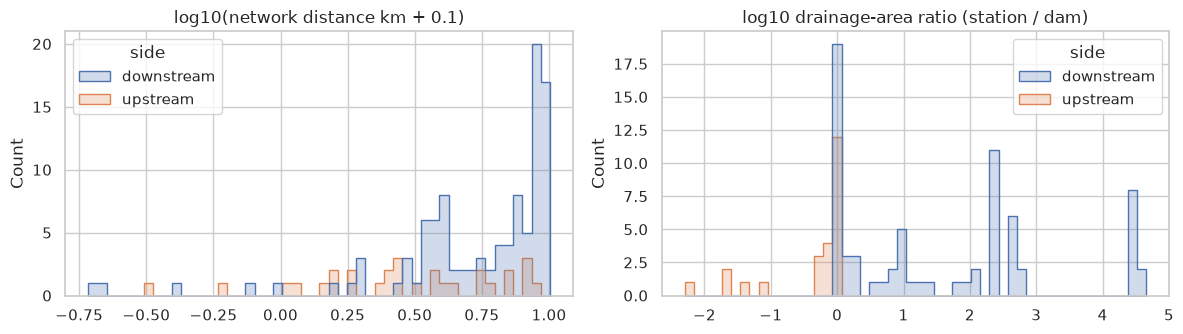

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(data=features, x="log10_distance_km", hue="side", element="step", bins=50, ax=axes[0])
axes[0].set(title="log10(network distance km + 0.1)", xlabel="")
sns.histplot(data=features, x="log10_drainage_area_ratio", hue="side", element="step", bins=50, ax=axes[1])
axes[1].set(title="log10 drainage-area ratio (station / dam)", xlabel="")
fig.tight_layout()
plt.show()

In [38]:
# Key numbers for the summary below.
b = exposure_rules.set_index("stage")
print("Exposure rules (rows / measurements / pairs / dams):")
for stage, r in b.iterrows():
    print(f"  {stage}: {r['rows']:,.0f} / {r['measurements']:,.0f} / {r['pairs']:,.0f} / {r['dams']:,.0f}")
print(f"Daily aggregation: {int(daily_compare['raw_rows'].sum()):,} -> {int(daily_compare['daily_rows'].sum()):,} rows "
      f"({100 * (1 - daily_compare['daily_rows'].sum() / daily_compare['raw_rows'].sum()):.1f}% fewer)")
print(f"Co-located copies: {old_copies:,} -> {new_copies:,} after requiring repeated agreement")
print(f"Non-riverine stations: {int(stations['non_riverine'].sum())} -> {int(stations['non_riverine_refined'].sum())}")
print(f"Far-snapped stations: {len(far)} ({int((~far['name_matches']).sum())} with a name mismatch)")
kept = q(f"SELECT count(DISTINCT AR_ID) AS dams, count(DISTINCT pair) AS pairs, count(DISTINCT station_id) AS stations "
         f"FROM pair_series_ids WHERE {PROPOSED}").iloc[0]
print(f"Proposed coverage rule keeps {kept['dams']} dams, {kept['pairs']} pairs, {kept['stations']} stations (any series)")
print(f"Dam snapping: {(dam_check['verdict'] == 'likely wrong').sum()} likely wrong, {(dam_check['verdict'] == 'check').sum()} "
      f"to check, of {len(dam_check)} analysis dams")
print(f"Station snapping: {(station_check['verdict'] == 'likely wrong').sum()} likely wrong "
      f"(of {(station_check['area'] != 'not reported').sum()} stations with a reported drainage area), "
      f"{(station_check['verdict'] == 'check').sum()} to check")

Exposure rules (rows / measurements / pairs / dams):
  A. all links: 69,747 / 46,236 / 133 / 54
  B. nearest upstream removal (downstream stations): 36,957 / 36,957 / 81 / 36
  C. exclude pairs with competing removals: 13,214 / 13,214 / 39 / 23
Daily aggregation: 412,597 -> 376,529 rows (8.7% fewer)
Co-located copies: 15,427 -> 419 after requiring repeated agreement
Non-riverine stations: 5 -> 0
Far-snapped stations: 5 (0 with a name mismatch)
Proposed coverage rule keeps 51 dams, 122 pairs, 78 stations (any series)
Dam snapping: 0 likely wrong, 8 to check, of 54 analysis dams
Station snapping: 0 likely wrong (of 21 stations with a reported drainage area), 0 to check


## Summary

**Main findings** (numbers from the `all_removals` run, and the cell above for sections 9–16)
- Values are mostly clean: wrong-looking values, unit slips and inconsistent visits are each under 1% of rows. The real issues are structural.
- **Competing removals** affect about 75% of rows. Excluding them (rule C) leaves roughly a quarter of the dams, so one-exposure-per-measurement (rule B) or modeling the overlap is the more practical route. Section 9 shows how often B's choice is clear-cut.
- **Reuse**: each measurement appears in about 2.2 pairs under rule A; rule B brings this to 1.
- **Same-day readings** are common (70% of water-temperature rows). Daily aggregation that keeps depth, sample type and method apart cuts rows substantially, and changes station concentration (section 10).
- **Concentration**: the top 1% of stations supply about a quarter of the rows; the Mid-Atlantic and STORET dominate.
- **Snapping**: the far snaps are mostly wide rivers and estuaries (fine); 7 stations are confirmed on the wrong reach. Sections 13–14 test dams and stations for wrong snaps at *any* distance (name, nearby alternatives, confluence ambiguity, reported drainage area); see the counts above.
- **Dilution proxy**: downstream stations typically drain far more area than the dam (median ratio about 73), so most stations see diluted removal signals.

**Added in sections 9–14:** a comparison of exposure rules A/B/C with an assignment-reliability check; daily aggregation (`daily_measurements.parquet`); co-located duplicates classified by repeated agreement; a refined non-riverine flag; a table and map of the far-snapped stations; dam and station snapping checks with a map of flagged dams (`dam_snap_check.csv`, `station_snap_check.csv`, `dam_snap_check_map.html`); eligibility under the proposed coverage rule, with threshold sensitivity and imbalance; spatial-feature availability and the upstream reservoir classes. New outputs: `exposure_rules.csv`, `exposure_nearest_upstream.parquet`, `daily_measurements.parquet`, `colocated_station_pairs.csv`, `far_snapped_stations.csv`, `far_snapped_stations_map.html`, `eligibility_by_series.csv`. Original measurements are unchanged.

**Unresolved before modeling**
1. Exposure rule: A (with station clustering), B, or C, and whether to add "other removals in the window" as a feature.
2. Whether to model daily aggregates, and how to treat depth profiles and days that mix censored and measured values.
3. Whether to drop `likely duplicate` co-located copies; exclude or correct the 7 confirmed wrong stations and any reviewed `likely wrong` dams and stations. If wrong dam snaps turn out to be common, approve a snapping fix and rerun from `snap_features`.
4. Final coverage thresholds (section 15), and which series to model.
5. Weighting or aggregation for station and regional imbalance; whether upstream pairs possibly in former reservoirs count as treated sites.

**Limitations from unavailable fields**
- The snapping checks depend on names (missing for unnamed reaches or dams without `River`) and on agency-reported drainage areas (mostly USGS stations); dams have no reported drainage area to compare.
- Dams still standing aren't in the data, so "nearest upstream removal" may not be the nearest barrier.
- Reported coordinates are in the station's own datum (not reprojected), so offsets of a few metres are datum shifts.
- The method ID exists only in `wq_measurement_raw`.
- The reservoir screen needs dam height (missing for about a quarter of pairs) and NHDPlus slope, and is a rough approximation.
- Drainage areas are NHDPlus values at each reach's downstream end.